# Transfer learning: ResNet-18 и MobileNetV2

В этот раз мы продолжим работать с изображениями и обсудим, как адаптировать уже обученные
модели под свои задачи. Но сначала разберём, из чего состоит современная свёрточная сеть
и зачем ей **global average pooling**, **batch normalization** и **residual connections**.

План практики:
1. **ResNet изнутри** — почему глубокие сети не обучаются без residual connections,
   зачем нужны BatchNorm и global average pooling, и как из этих же идей собирается
   лёгкая MobileNet (depthwise separable свёртки, inverted residual);
2. **Инструменты** — обучающий цикл на чистом PyTorch, метрики `torchmetrics` и замер
   времени обучения и инференса;
3. **Стратегии переноса знаний** — серия экспериментов на Oxford-IIIT Pet: от обучения
   с нуля до полного файнтюна; в каждом меняем ровно одну вещь; каждый эксперимент
   повторяем на двух бэкбонах — тяжёлом ResNet-18 и лёгком MobileNetV2 — и сравниваем
   качество, время обучения и скорость инференса;
4. **Аугментации** — когда они помогают, а когда бесполезны;
5. **Типичные ошибки** — как по кривым обучения и быстрым проверкам поймать частые
   баги при дизайне и реализации таких сетей.

Полезные ссылки:
- [ResNet: Deep Residual Learning (статья)](https://arxiv.org/abs/1512.03385)
- [MobileNetV2: Inverted Residuals and Linear Bottlenecks (статья)](https://arxiv.org/abs/1801.04381)

In [1]:
# --- стандартные библиотеки ---
import copy  # deepcopy: шаги 3 и 5 стартуют с копией модели, обученной на шаге 2
import time  # замер времени обучения и инференса
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchmetrics
import tqdm.auto
from IPython.display import Image, display
from PIL import Image as PILImage
from torch import nn
from torchvision import transforms
from torchvision.models import MobileNet_V2_Weights, ResNet18_Weights, mobilenet_v2, resnet18

from utils.common import seed_everything
from utils.plotting import plot_train_history, show_image_batch
from utils.plotting import IMAGENET_MEAN, IMAGENET_STD

from utils.data import make_dataloaders
%matplotlib inline
warnings.filterwarnings("ignore")

seed_everything(123)  # фиксируем случайности: все стратегии обучаются при прочих равных

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch: {torch.__version__}, device: {device}")
if device.type == "cuda":
    print(f"gpu: {torch.cuda.get_device_name(0)}")

torch: 2.14.0+cpu, device: cpu


## Данные: Oxford-IIIT Pet

В этой практике рассмотрим [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/) — датасет, содержащий 37 классов пород кошек и
собак, ~3.7 тысяч обучающих изображений (около 100 на класс).

Мы сталкиваемся с двумя проблемами сразу:
- датасет достаточно маленький, и информации по каждому классу не очень много.
- даже с учетом этого обучить модель с нуля может быть сложно

Картинки при этом довольно похожи на «обычные» фотографии, поэтому можно перенести знания какой-нибудь мощной модели, обученной на большом датасете, на нашу задачу. Чаще всего для этого
используется файн-тюнинг: модель, обученная на большом датасете, уже умеет выделять хорошие признаки из изображений — возьмём её веса и слегка подстроим под новую задачу.


In [2]:
train_loader, val_loader, test_loader, num_classes, classes = make_dataloaders(batch_size=64)

print(f"train: {len(train_loader.dataset)} | val: {len(val_loader.dataset)} | test: {len(test_loader.dataset)}")
print(f"классов: {num_classes}, первые 5: {classes[:5]}")


train: 2944 | val: 736 | test: 3669
классов: 37, первые 5: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle']


saved: ..\images\dataset_samples.png


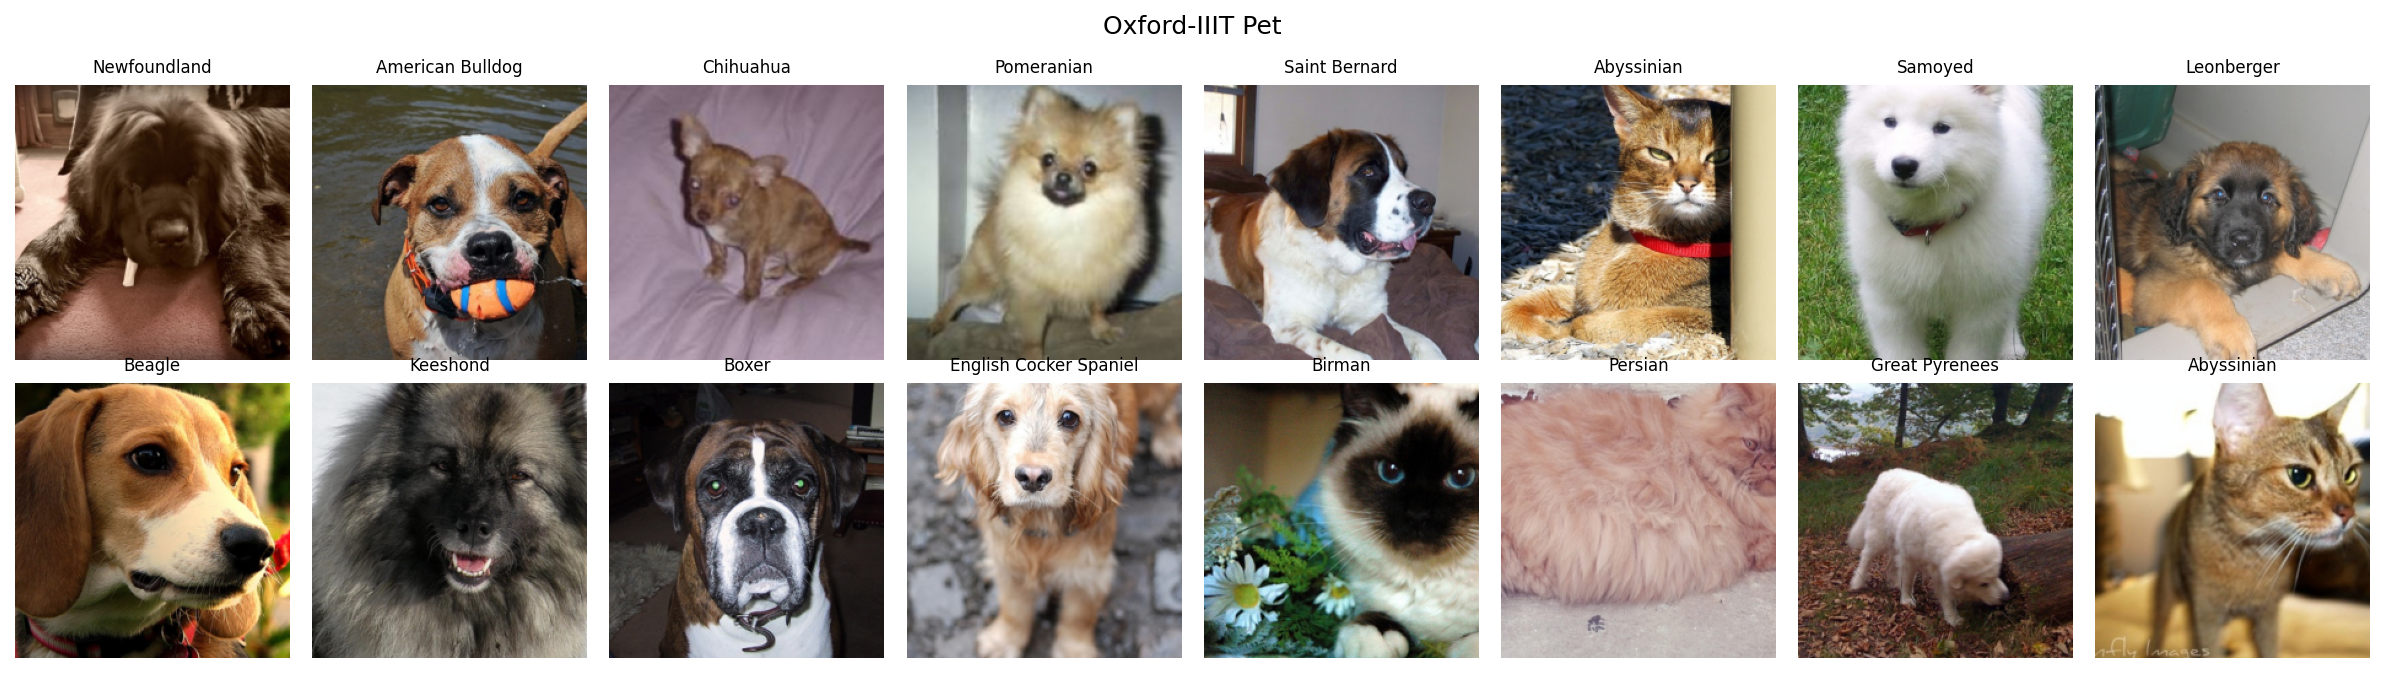

In [3]:

images, labels = next(iter(train_loader))
show_image_batch(
    images, labels, classes,
    save_path="../images/dataset_samples.png",
    title="Oxford-IIIT Pet",
    mean=IMAGENET_MEAN,
    std=IMAGENET_STD,
)
display(Image(filename="../images/dataset_samples.png"))


*Задание*: выведите случайный элемент датасета. 

индекс в обучающем subset: 2504, класс: Miniature Pinscher
saved: ..\images\random_pet.png


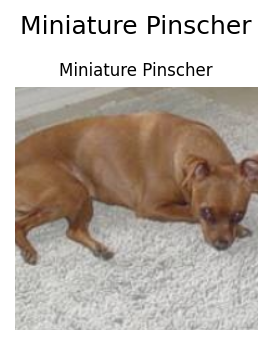

In [4]:
sample_index = int(np.random.default_rng(0).integers(len(train_loader.dataset)))
sample_image, sample_label = train_loader.dataset[sample_index]
print(f"индекс в обучающем subset: {sample_index}, класс: {classes[sample_label]}")
show_image_batch(
    sample_image.unsqueeze(0),
    [sample_label],
    classes,
    save_path="../images/random_pet.png",
    title=classes[sample_label],
    mean=IMAGENET_MEAN,
    std=IMAGENET_STD,
)
display(Image(filename="../images/random_pet.png"))


## Предобученные модели
В `torchvision` реализовано множество моделей (ResNet, VGG, AlexNet, DenseNet, ResNext, WideResNet, MobileNet, ...) вместе с чекпоинтами на ImageNet — см. [документацию моделей](https://pytorch.org/vision/stable/models.html). ImageNet - это огромный датасте на 1000 классов, который долгое время использовался как основвное средство для получения достаточно сильных моделей и их сравнения.

Для начала загрузим модель ResNet-18.

In [5]:
model = resnet18(weights=ResNet18_Weights.DEFAULT)
model = model.to(device)
model.eval()  # почему это важно?

print(f"всего параметров: {sum(p.numel() for p in model.parameters()):,}")
print(f"модель на устройстве: {next(model.parameters()).device}")

# почему eval: дальше идут одиночные картинки. В train() BatchNorm нормировал бы их
# статистиками батча размера 1, а Dropout выключал бы случайные каналы. eval() берёт
# накопленные running_mean/running_var и отключает Dropout, поэтому ответ стабильный.


всего параметров: 11,689,512
модель на устройстве: cpu


Несмотря на то, что эта модель считается достаточно простой и маленькой, у нее уже 11 миллионов параметров, обучать ее может быть непросто. Нол попробуем проверить, может, модель изначально ничего. 

In [6]:
def predict_imagenet(model, x: torch.Tensor, top_n: int = 5):

    with torch.no_grad():
        logits = model(x.float())
    probs = torch.softmax(logits, dim=-1)[0].cpu()  # вероятности по 1000 классам, не нашим!
    categories = ResNet18_Weights.DEFAULT.meta["categories"]
    top = probs.topk(top_n)
    return {categories[int(idx)]: float(prob) for prob, idx in zip(top.values, top.indices)}

Сделаем предсказания на случайных картинках:

In [7]:

idx = np.random.randint(len(train_loader.dataset))

# препроцессинг делается как при обучении : масштаб -> центральный кроп 224x224 ->
# тензор [0, 1] -> нормализация статистиками ImageNet

image, label = train_loader.dataset[idx] 
image = image.to(device).unsqueeze(0)
print(f"истинный класс: {classes[label]}")
predict_imagenet(model, image)


истинный класс: Egyptian Mau


{'Egyptian cat': 0.9985727071762085,
 'tabby': 0.000543670728802681,
 'snow leopard': 0.0003382024588063359,
 'tiger cat': 0.00020948062592651695,
 'lynx': 0.00016370974481105804}

*Задание*: попробуйте свои картинки. Сделайте препроцессинг, соответствующий Imagenet. Ответьте, как отличается уверенность модели для классов, близких к imagenet и далеких от него.


In [8]:
from pathlib import Path

imagenet_preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Кот и котёнок — объекты, близкие к классам ImageNet.
# pacanoids и схема GPT-2 к этим классам не относятся.
own_images = [
    ("kitten.jpg", "близко: котёнок"),
    ("kot_mjaukaet.jpg", "близко: кот"),
    ("pacanoids.jpg", "фото не из классов ImageNet"),
    ("gpt-2.png", "далеко: схема"),
]
model.eval()
for filename, note in own_images:
    pil = PILImage.open(Path("..") / "images" / filename).convert("RGB")
    batch = imagenet_preprocess(pil).unsqueeze(0).to(device)
    top = predict_imagenet(model, batch)
    top_name, top_prob = next(iter(top.items()))
    print(f"{note} ({filename}): top-1 {top_name} {top_prob:.3f}; {top}")


близко: котёнок (kitten.jpg): top-1 ping-pong ball 0.115; {'ping-pong ball': 0.1149233803153038, 'pill bottle': 0.09546355158090591, 'Angora': 0.050568193197250366, 'fur coat': 0.030753064900636673, 'lab coat': 0.025960229337215424}
близко: кот (kot_mjaukaet.jpg): top-1 Egyptian cat 0.246; {'Egyptian cat': 0.24595458805561066, 'Arctic fox': 0.07430072128772736, 'screen': 0.04088409245014191, 'Siamese cat': 0.034754492342472076, 'weasel': 0.02950509451329708}
фото не из классов ImageNet (pacanoids.jpg): top-1 maraca 0.253; {'maraca': 0.25289246439933777, 'piggy bank': 0.1553477793931961, 'ocarina': 0.15152572095394135, 'football helmet': 0.06557038426399231, 'whistle': 0.056169360876083374}


далеко: схема (gpt-2.png): top-1 hand-held computer 0.137; {'hand-held computer': 0.13674604892730713, 'stopwatch': 0.06581549346446991, 'web site': 0.05255063250660896, 'hard disc': 0.04645243659615517, 'scale': 0.039338622242212296}


**Ответ.** Уверенность на всех четырёх кадрах невысокая. Близость к объектам ImageNet сама по себе не собирает вероятность на правильном классе.

`kot_mjaukaet.jpg`: top-1 Egyptian cat 0.246, Siamese cat только 0.035. Кота модель узнаёт, но масса вероятности остаётся на других классах.

`kitten.jpg`: top-1 ping-pong ball 0.115. Из животных в top-5 только Angora с 0.051, остальные метки — pill bottle, fur coat, lab coat.

`pacanoids.jpg`: top-1 maraca 0.253, рядом piggy bank и ocarina. Кадр не из классов ImageNet, ярлык выбран по форме.

`gpt-2.png`: top-1 hand-held computer 0.137, дальше stopwatch, web site, hard disc, scale. Схема не входит в 1000 классов, и вероятность размазана. Голова всё равно обязана назвать один из них.


## ResNet

### Проблема глубины

Исследователи заметили: чем глубже свёрточная сеть, тем лучше — гибкость модели растёт с числом параметров. Но начиная с некоторой глубины точность перестаёт расти и начинает **падать**
(причём даже на обучающей выборке — это не переобучение, а проблема оптимизации).

*Вопрос:* с чем связано это явление? (подсказка: подумайте, что происходит с градиентами
на ранних слоях при распространении ошибки через десятки слоёв)
**Ответ.** Это проблема оптимизации, а не переобучения: падает даже обучающая точность. Градиент раннего слоя — произведение якобианов всех слоёв выше. Если их спектральный радиус меньше единицы, произведение затухает, и ранние слои почти не получают сигнал. Глубокая сеть тогда не может повторить решение мелкой (для этого верхним слоям достаточно выучить преобразование, близкое к тождественному). Residual как раз добавляет к якобиану единичную матрицу, так что путь с множителем 1 никуда не девается.

### Residual connections

Так появилось семейство ResNet. Идея следующая: если модель может предсказать $f(x)$, то она может
предсказать и $f(x) - x$. Вместо $x_{l+1} = F(x_l)$ учим

$$x_{l+1} = x_l + F(x_l), \qquad \frac{\partial x_{l+1}}{\partial x_l} = \mathbf{I} + \frac{\partial F(x_l)}{\partial x_l}$$

Слагаемое $\mathbf{I}$ гарантирует, что градиент «дошёл» до глубинных слоёв даже если $\partial F / \partial x \approx 0$ — исчезающих градиентов стало намного меньше, и
обучать сотни слоёв реально.

![resnet](../images/resnet.png)


Рассмотрим модель по частям.  Обычный блок (BasicBlock) выглядит так:

```
Input: x
[Conv 3x3] -> [BatchNorm] -> [ReLU] -> [Conv 3x3] -> [BatchNorm]
Add: x + F(x)
[ReLU]
```


In [9]:
basic_block = model.layer1[0]
basic_block


BasicBlock(
  (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
)

*Вопрос*: почему в свёртках `bias=False`?

**Ответ.** Сразу за свёрткой стоит BatchNorm, а у него есть свой сдвиг $\beta$. BN вычитает среднее, поэтому постоянный bias свёртки всё равно обнуляется и на выход не влияет. `bias=False` убирает параметры, которые нечему было бы выучить.


### BatchNorm

Batch Normalization нормирует активации каждого канала по текущим батчем:

$$\hat{x}_{ijk} = \frac{x_{ijk} - \mathrm{E}_B[x_{ijk}]}{\sqrt{\mathrm{Var}_B[x_{ijk}] + \varepsilon}}, \qquad y_{ijk} = \gamma_k \hat{x}_{ijk} + \beta_k$$

Зачем это нужно:
- «выравнивает» масштаб активаций, обучение сходится быстрее и стабильнее
- позволяет использовать больший learning rate
- немного регуляризует сеть (добавляя шум от случайных батчей)

Важный нюанс: в режиме `train()` BN считает статистики по батчу и обновляет бегущие
средние (`running_mean`/`running_var`), а в `eval()` использует накопленные.
Поэтому **при инференсе и при файнтюнинге замороженной части модель должна быть в `eval()`**,
иначе маленькие батчи будут портить статистики.

Для демонстрации прогоним случайный батч через свёртку и BatchNorm (в режиме `train`)
и сравним статистики активаций до и после нормализации.


In [10]:
demo_conv = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False).to(device)
demo_bn = nn.BatchNorm2d(64).to(device).train()

x = torch.randn(8, 3, 224, 224, device=device)
with torch.no_grad():
    before_bn = demo_conv(x)  # активации свёртки -- с какими-то своими средним и разбросом
    after_bn = demo_bn(before_bn)

print(f"до BN:   mean={before_bn.mean():+.3f}  std={before_bn.std():.3f}")
print(f"после BN: mean={after_bn.mean():+.3f}  std={after_bn.std():.3f}")


до BN:   mean=-0.000  std=0.568
после BN: mean=+0.000  std=1.000


После свёртки распределение активаций «как получится», после BN — почти стандартное
(среднее ~0, разброс ~1). Именно на такие активации и рассчитаны последующие слои.


### Bottleneck

Глубокие ResNet (50, 101, 152) используют не двухслойные, а bottleneck-блоки из трёх свёрток:

```
[Conv 1x1] -> [BN + ReLU]   # сжимаем число каналов (дешевле)
[Conv 3x3] -> [BN + ReLU]   # основная свёртка
[Conv 1x1] -> [BN]          # возвращаем/расширяем каналы
```

*Вопрос*: почему основная свёртка именно 3×3, а не 5×5 или 7×7 и зачем нужны свертки 1х1?

**Ответ.** Две свёртки 3×3 дают рецептивное поле 5×5, три — 7×7, но весов меньше, чем у одного широкого ядра: $2\cdot 9=18$ против $25$ и $3\cdot 9=27$ против $49$, и между 3×3 есть нелинейности. Поэтому основное пространственное ядро — 3×3, а не 5×5 или 7×7.

Свёртка 1×1 соседей не смотрит, зато дёшево меняет число каналов. В bottleneck первая 1×1 сжимает ширину, дорогая 3×3 работает в узком месте, последняя 1×1 возвращает число каналов. Без них 3×3 пришлось бы считать на полной ширине блока.


In [11]:
from torchvision.models import resnet50

# weights=None: нужна только структура блока, тащить 100 МБ весов незачем
bottleneck_block = resnet50(weights=None).layer1[0]  # первый блок первой группы
print(f"параметров в bottleneck-блоке: {sum(p.numel() for p in bottleneck_block.parameters()):,}")
bottleneck_block


параметров в bottleneck-блоке: 75,008


Bottleneck(
  (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (downsample): Sequential(
    (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
)

### Экономная свёртка: depthwise separable convolution (MobileNet)

Обычная свёртка k×k делает сразу две работы: **пространственную фильтрацию** (смотрим
окрестность пикселя) и **смешивание каналов** (собираем информацию между каналами). Цена —
$k^2 \cdot C_{in} \cdot C_{out}$ умножений на каждый выходной пиксель, и для мобильных
устройств это слишком дорого.

Идея MobileNet — разделить эти работы на две дешёвые свёртки:
1. **depthwise** k×k: каждый канал фильтруется отдельно (`groups=C_in` в `nn.Conv2d`),
   цена $k^2 \cdot C_{in}$;
2. **pointwise** 1×1: смешивает каналы, цена $C_{in} \cdot C_{out}$.

Экономия — $\frac{1}{C_{out}} + \frac{1}{k^2}$ раз: для ядер 3×3 это примерно **8–9×**.
Посчитаем и проверим на PyTorch:


In [12]:

c_in, c_out, k, h, w = 32, 64, 3, 112, 112

x = torch.randn(1, c_in, h, w)
depthwise = nn.Conv2d(c_in, c_in, k, padding=1, groups=c_in, bias=False)
pointwise = nn.Conv2d(c_in, c_out, kernel_size=1, bias=False)
full = nn.Conv2d(c_in, c_in, k, padding=1, bias=False)
dw_pw = sum(p.numel() for p in depthwise.parameters()) + sum(p.numel() for p in pointwise.parameters())
print(f"параметров: {sum(p.numel() for p in depthwise.parameters()):,} (dw) + "
      f"{sum(p.numel() for p in pointwise.parameters()):,} (pw) = {dw_pw:,} против {sum(p.numel() for p in full.parameters()):,} у обычной")
pointwise(depthwise(x)).shape


параметров: 288 (dw) + 2,048 (pw) = 2,336 против 9,216 у обычной


torch.Size([1, 64, 112, 112])

Из таких свёрток MobileNetV2 собирает блок **inverted residual** — знакомый по ResNet
bottleneck, но «вывернутый наизнанку»:

| | ResNet bottleneck | MobileNetV2 inverted residual |
|---|---|---|
| каналы | сжатие каналов → тяжелая свертка  → расширение каналов | расширение каналов (в 6 раз) → тяжелая свертка → сжатие каналов обратно |
| свёртки | 1×1 → **3×3** → 1×1 | 1×1 → **3×3 depthwise** → 1×1 |
 
При этом:
- финальная 1×1 свертка в mobilenet— **linear bottleneck**. За счет избыточности большого числа каналов потеря информации - не проблема, но вот уже в низкоразмерном пространсве после сжатия обратно мы обязательно теряем много полезного сигнала. ПОэтому в конце блока активация не применяется -  это только проекция.
- skip connection делается тоже в низкоразмерном пространстве - так мы дополнительно экономим память. 
- вместо ReLU — **ReLU6** (ыыход дополнительно обрезается на 6): стабильнее при квантовании весов в int8.

*Вопрос*: почему расширение ×6 в середине блока «почти бесплатное», хотя каналов становится
в 6 раз больше?

**Ответ.** Расширение стоит перед depthwise-свёрткой, а не перед обычной. Обычная 3×3 на ширине $6C$ стоила бы $9\cdot 6C\cdot 6C = 324C^2$ весов. Depthwise на тех же $6C$ каналах стоит $9\cdot 6C = 54C$: линейно по ширине, а не квадратично. Дорожают только две свёртки 1×1, $C\to 6C$ и $6C\to C$, вместе $12C^2$. На фоне полной свёртки той же ширины лишние каналы почти бесплатны, поэтому внутри блока их и раздувают в 6 раз.


In [13]:
from torchvision.models import mobilenet_v2

# weights=None: как и с bottleneck из ResNet-50 выше, для структуры веса не нужны
mbnet = mobilenet_v2(weights=None)
print(f"MobileNetV2: {sum(p.numel() for p in mbnet.parameters()):,} параметров"
      f" против {sum(p.numel() for p in model.parameters()):,} у ResNet-18")
print(f"skip connection у этого блока: {mbnet.features[3].use_res_connect}")
mbnet.features[3]  # inverted residual: 24 -> 144 (1x1, x6) -> depthwise 3x3 -> 24 (1x1, linear bottleneck)


MobileNetV2: 3,504,872 параметров против 11,689,512 у ResNet-18
skip connection у этого блока: True


InvertedResidual(
  (conv): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(24, 144, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): BatchNorm2d(144, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): Conv2dNormActivation(
      (0): Conv2d(144, 144, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=144, bias=False)
      (1): BatchNorm2d(144, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (2): Conv2d(144, 24, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (3): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
)

### Global average pooling (avgpool)

Как из карт признаков получить ответ классификатора? В старых сетях (VGG) делали так:
`Flatten` карт 512×7×7 = 25088 чисел -> `Linear(25088, 4096)` -> ... — только классификатор
VGG-16 весит больше 100M параметров и сильно переобучается.

И ResNet, и MobileNet заканчивается **глобальным средним пулингом**: `AdaptiveAvgPool2d((1, 1))` усредняет
каждую карту признаков до одного числа -> на выходе 512 чисел -> один `Linear(512, num_classes)`.

Преимущества:
- на несколько порядков меньше параметров в голове -> меньше переобучения;
- каждый канал карты признаков фактически становится своим «детектором понятия»;
- `AdaptiveAvgPool2d` работает с любым размером входа.

Сравним количество параметров двух вариантов головы для резнета:


In [14]:
print(model.avgpool)
print(model.fc)


def count_parameters(module: nn.Module) -> int:
    return sum(p.numel() for p in module.parameters())


# два способа превратить карты признаков (512, 7, 7) в логиты классов
flat_head = nn.Sequential(nn.Flatten(), nn.Linear(512 * 7 * 7, num_classes))  # «по-vggшному»
avg_head = nn.Sequential(nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(), nn.Linear(512, num_classes))  # «по-реснетовски»

print(f"голова Flatten + Linear: {count_parameters(flat_head):,} параметров")
print(f"голова avgpool + Linear: {count_parameters(avg_head):,} параметров")
print(f"разница: {count_parameters(flat_head) / count_parameters(avg_head):.0f}x")


AdaptiveAvgPool2d(output_size=(1, 1))
Linear(in_features=512, out_features=1000, bias=True)
голова Flatten + Linear: 928,293 параметров
голова avgpool + Linear: 18,981 параметров
разница: 49x


Задание: сделайте такое же сравнение для mobilenet. Сколько весов у его головы?

In [15]:
# Последняя карта MobileNetV2 — 1280 каналов 7x7, как у входа в classifier.
# Родная голова смотрит на 1000 классов ImageNet: веса мы не подменяли.
mb_flat = nn.Sequential(nn.Flatten(), nn.Linear(1280 * 7 * 7, num_classes))
mb_avg = nn.Sequential(nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(), nn.Linear(1280, num_classes))
print("classifier:", mbnet.classifier)
print(f"родная голова ImageNet, Linear(1280, 1000): {count_parameters(mbnet.classifier):,} параметров")
print(f"Flatten + Linear на {num_classes} классов: {count_parameters(mb_flat):,}")
print(f"avgpool + Linear на {num_classes} классов: {count_parameters(mb_avg):,}")
print(f"разница: {count_parameters(mb_flat) / count_parameters(mb_avg):.0f}x")
print(
    "У ResNet голова после avgpool — Linear(512, num_classes), "
    f"у MobileNet — Linear(1280, num_classes), то есть примерно в {1280 / 512:.1f} раза шире. "
    "Глобальный пулинг и здесь убирает множитель 7x7=49."
)


classifier: Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)
родная голова ImageNet, Linear(1280, 1000): 1,281,000 параметров
Flatten + Linear на 37 классов: 2,320,677
avgpool + Linear на 37 классов: 47,397
разница: 49x
У ResNet голова после avgpool — Linear(512, num_classes), у MobileNet — Linear(1280, num_classes), то есть примерно в 2.5 раза шире. Глобальный пулинг и здесь убирает множитель 7x7=49.


## Transfer learning и файнтюнинг

Вернемся к основной задаче ноутбука. Мы хотим взять модель, обученную на каком-то большом датасете и обучить только частитчно на маленьком. Так мы сэкономим время на обучение и сбор данных.

Первое, что нужно сделать - полменять голову на подходящую (с нужным числом классов на выходе). Дальше есть варианты:

| Шаг | Что обучаем | Когда достаточно |
|---|---|---|
| 1. Фичи + классическая модель | ничего (сеть как экстрактор признаков) | данных совсем мало, нужна скорость |
| 2. Только голова | новый `fc` | данных мало, задача близка к ImageNet |
| 3. Все слои | вся сеть | данных побольше, задача специфична |

При полном файнтюнинге нужно задавать **маленький** learning rate: если резко двинуть все
веса, модель «забудет» полезные признаки, выученные на ImageNet. Рассмотрим разные варианты последовательно. Для начала напишем обучающий цикл и заодно добавим подсчет метрик с помощью torchmetrics.

In [16]:
def _computed_metrics(metric) -> dict:
    # torchmetrics возвращает число или словарь {имя: значение} -- приводим к общему виду
    computed = metric.compute()
    if isinstance(computed, dict):
        return {key: value.item() for key, value in computed.items()}
    return {"accuracy": computed.item()}


def train_epoch(model, data_loader, criterion, optimizer, metric, device):
    model.train()  # режим обучения: BN считает статистики по батчу, Dropout активен
    metric.reset()  # torchmetrics копят статистики -- обнуляем в начале каждой эпохи
    losses = []
    pbar = tqdm.auto.tqdm(data_loader, desc="  train", leave=False, disable=None)
    for inputs, targets in pbar:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad()  # иначе градиенты прошлых шагов накопятся с новыми
        preds = model(inputs)  # forward: (batch, num_classes)
        loss = criterion(preds, targets)
        loss.backward()  # backward: градиенты по всем обучаемым параметрам
        optimizer.step()  # шаг оптимизатора вдоль градиента

        metric.update(preds, targets)
        losses.append(loss.item())
        pbar.set_description(f"  train loss={losses[-1]:.4f}")
    metrics = {"loss": float(np.mean(losses))}
    metrics.update(_computed_metrics(metric))
    metric.reset()
    return metrics


@torch.no_grad()  # валидация: градиенты не нужны -- экономим память и время
def validate(model, data_loader, criterion, metric, device):
    model.eval()  # режим инференса: BN использует накопленные бегущие статистики
    metric.reset()
    losses = []
    pbar = tqdm.auto.tqdm(data_loader, desc="  val  ", leave=False, disable=None)
    for inputs, targets in pbar:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        preds = model(inputs)
        loss = criterion(preds, targets)

        metric.update(preds, targets)
        losses.append(loss.item())
        pbar.set_description(f"  val   loss={losses[-1]:.4f}")
    metrics = {"loss": float(np.mean(losses))}
    metrics.update(_computed_metrics(metric))
    metric.reset()
    return metrics


TIMING = {}  # реестр замеров: подпись эксперимента -> время обучения и инференса


def train(model, train_loader, val_loader, criterion, metric, optimizer, device, epochs=3, scheduler=None, label=""):
    # полный цикл обучения: эпоха train -> эпоха val -> шаг планировщика lr; история -- для графиков
    history = {}
    t_start = time.perf_counter()  # время обучения -- тоже честная метрика модели
    for epoch in range(epochs):
        print(f"Epoch {epoch + 1}/{epochs}")
        train_metrics = train_epoch(model, train_loader, criterion, optimizer, metric, device)
        val_metrics = validate(model, val_loader, criterion, metric, device)
        print(
            f"  train loss={train_metrics['loss']:.4f} | val loss={val_metrics['loss']:.4f}",
            "".join(f" | val {k}={v:.4f}" for k, v in val_metrics.items() if k != "loss"),
        )
        for key, value in train_metrics.items():  # копим историю для plot_train_history
            history.setdefault(f"train_{key}", []).append(value)
        for key, value in val_metrics.items():
            history.setdefault(f"val_{key}", []).append(value)
        if scheduler is not None:  # планировщик вызывается раз в эпоху
            scheduler.step()
    elapsed = time.perf_counter() - t_start
    print(f"обучение заняло {elapsed:.1f} c ({elapsed / epochs:.1f} c/эпоху)")
    if label:  # копим в TIMING для итоговой таблицы в «Сравнении стратегий»
        TIMING[label] = {"train_s": elapsed, "sec_per_epoch": elapsed / epochs}
    return history


@torch.no_grad()
def measure_inference_time(model, data_loader, device) -> tuple[float, float]:
    """Скорость инференса: (секунды на весь лоадер, картинок в секунду). Модель переводится в eval()."""
    model.eval()  # как в validate: BN -- с накопленными статистиками, Dropout выключен
    if device.type == "cuda":
        torch.cuda.synchronize()  # иначе таймер не увидит асинхронные CUDA-вычисления
    t_start = time.perf_counter()
    n_images = 0
    for inputs, _ in data_loader:
        model(inputs.to(device, non_blocking=True))
        n_images += inputs.size(0)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t_start
    return elapsed, n_images / elapsed


def report_inference_time(results: dict, step: str):
    # меряем скорость инференса каждой модели шага на val_loader и добавляем в TIMING
    for name, result in results.items():
        elapsed, images_per_s = measure_inference_time(result["model"], val_loader, device)
        TIMING.setdefault(f"{step} -- {name}", {})["infer_s"] = elapsed
        TIMING[f"{step} -- {name}"]["images_per_s"] = images_per_s
        print(f"{step} -- {name}: инференс val_loader -- {elapsed:.2f} c ({images_per_s:.0f} картинок/с)")


# --- два бэкбона, на которых повторяется каждый эксперимент практики ---
ARCHITECTURES = {
    "ResNet-18": resnet18,
    "MobileNetV2": mobilenet_v2,
}
IMAGENET_WEIGHTS = {
    "ResNet-18": ResNet18_Weights.DEFAULT,
    "MobileNetV2": MobileNet_V2_Weights.DEFAULT,
}
FEATURE_DIMS = {  # размер эмбеддингов без головы
    "ResNet-18": 512,
    "MobileNetV2": 1280,
}
SLUGS = {"ResNet-18": "", "MobileNetV2": "mobilenet_"}  # префиксы имён файлов с графиками


def get_model(name: str, num_out_classes: int, pretrained: bool = True, freeze: bool = False) -> nn.Module:
    """ResNet-18 или MobileNetV2 с новой классификационной головой.

    name       -- ключ ARCHITECTURES;
    pretrained -- загружать ли веса ImageNet;
    freeze     -- заморозить ли все слои, кроме финального Linear.
    """
    model = ARCHITECTURES[name](weights=IMAGENET_WEIGHTS[name] if pretrained else None)
    if freeze:
        # порядок важен: сначала замораживаем ВСЕ параметры...
        for param in model.parameters():
            param.requires_grad = False
    # ...и только потом заменяем голову: параметры нового Linear по умолчанию обучаемы.
    # Головы у torchvision устроены по-разному: у ResNet это model.fc, у MobileNetV2 --
    # model.classifier = Sequential(Dropout, Linear(1280, 1000)), т.е. Linear -- classifier[1].
    if name == "ResNet-18":
        model.fc = nn.Linear(model.fc.in_features, num_out_classes)
    else:
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_out_classes)
    return model


def get_head(name: str, model: nn.Module) -> nn.Module:
    """Финальный Linear (голова) для любой из двух архитектур."""
    return model.fc if name == "ResNet-18" else model.classifier[1]


def count_trainable_parameters(model: nn.Module) -> int:
    # быстрая проверка «что именно мы обучаем»: выручает, когда случайно разморозили лишнее
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def plot_step_histories(results: dict, titles: dict, prefix: str):
    # график истории обучения для каждой архитектуры текущего шага
    for name, result in results.items():
        path = f"../images/{SLUGS[name]}{prefix}_history.png"
        plot_train_history(result["history"], titles[name], path)
        display(Image(filename=path))


criterion = nn.CrossEntropyLoss()  # лосс один на все эксперименты ниже

## Метрики: torchmetrics

[torchmetrics](https://lightning.ai/docs/torchmetrics/stable/) — библиотека для аккуратного
подсчёта метрик: они копят статистики по батчам и корректно агрегируются в конце эпохи. Эта библиотека легко расширяется и изначально содержит большую часть полезных для торча метрик. 

Заведём accuracy для обучающего цикла и набор метрик для финальной оценки.


In [17]:
# метрика для обучающего цикла (её печатаем после каждой эпохи)
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=num_classes).to(device)

# набор метрик для финальной оценки лучшей модели
full_metric = torchmetrics.MetricCollection(
    {
        "accuracy": torchmetrics.Accuracy(task="multiclass", num_classes=num_classes),
        "precision_macro": torchmetrics.Precision(task="multiclass", num_classes=num_classes, average="macro"),
        "recall_macro": torchmetrics.Recall(task="multiclass", num_classes=num_classes, average="macro"),
        "precision_micro": torchmetrics.Precision(task="multiclass", num_classes=num_classes, average="micro"),
        "recall_micro": torchmetrics.Recall(task="multiclass", num_classes=num_classes, average="micro"),
    }
).to(device)  # метрики живут на том же устройстве, что и предсказания


`average="micro"` и `average="macro"` считают точность по-разному:

- **micro** — просто доля правильных ответов по всем примерам (классы с большим числом
  примеров влияют сильнее);
- **macro** — среднее метрики по классам (все классы равноправны; чувствительно к качеству
  на редких классах).


In [18]:
# мини-пример на 10 ответах: micro -- доля правильных ответов, macro -- среднее
# accuracy по классам (класс 0 угадан целиком, класс 1 -- наполовину)
toy_preds = torch.tensor([0, 0, 0, 0, 0, 1, 1, 2, 2, 2])
toy_targets = torch.tensor([0, 0, 1, 1, 1, 1, 2, 2, 2, 2])

micro = torchmetrics.Accuracy(task="multiclass", num_classes=3, average="micro")
macro = torchmetrics.Accuracy(task="multiclass", num_classes=3, average="macro")
print(f"micro: {micro(toy_preds, toy_targets):.3f}")  # 6 верных из 10
print(f"macro: {macro(toy_preds, toy_targets):.3f}")  # среднее accuracies классов: (1.0 + 0.25 + 0.75) / 3


micro: 0.600
macro: 0.667


*Задание*: добавьте в `full_metric` Precision/Recall с `average="micro"` и сравните с macro-версиями
на нашей задаче. В каких ситуациях та или иная настройка лучше отражает качество предсказаний?

**Ответ.** Для multiclass с одним верным классом micro-precision, micro-recall и accuracy совпадают: это одна и та же доля верных ответов, крупные классы тянут её сильнее. Macro усредняет метрику по классам и проседает, если несколько пород узнаются плохо, даже когда большинство примеров классифицировано верно.

На Oxford Pet классы почти равные (около 100 картинок на породу), поэтому micro и macro здесь близки. Micro полезнее, когда важно общее число ошибок и классы несбалансированы. Macro — когда редкий класс нельзя закрыть успехом частого: например, если одна порода почти не встречается, но её ошибки так же важны.


## Бейзлайн

Прежде чем переносить знания, убедимся, что «с нуля» на нашем маленьком датасете всё
плохо. Обучим обе сети — ResNet-18 и MobileNetV2 — со случайной инициализацией.
есть аргумент `num_classes`, который сразу заменяет голову под нашу задачу.

In [19]:
results_scratch = {}  # имя архитектуры -> {"model": ..., "history": ...}

for name in ARCHITECTURES:
    print(f"\n=== {name}: обучение с нуля ===")
    seed_everything(123)
    model = get_model(name, num_classes, pretrained=False, freeze=False).to(device)  # случайные веса + сразу нужная голова
    print(f"модель на устройстве: {next(model.parameters()).device}")

    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = train(
        model, train_loader, val_loader, criterion, accuracy_metric, optimizer, device,
        epochs=10, label=f"шаг 0: с нуля -- {name}",
    )
    results_scratch[name] = {"model": model, "history": history}

report_inference_time(results_scratch, "шаг 0: с нуля")


=== ResNet-18: обучение с нуля ===
модель на устройстве: cpu
Epoch 1/10


  train loss=3.4965 | val loss=3.7761  | val accuracy=0.0761
Epoch 2/10


  train loss=3.1545 | val loss=3.9853  | val accuracy=0.0815
Epoch 3/10


  train loss=2.9524 | val loss=3.6603  | val accuracy=0.1291
Epoch 4/10


  train loss=2.7483 | val loss=3.5800  | val accuracy=0.1291
Epoch 5/10


...

  train loss=2.3766 | val loss=4.0134  | val accuracy=0.1617
Epoch 9/10


  train loss=2.1428 | val loss=4.0243  | val accuracy=0.1535
Epoch 10/10


  train loss=1.9545 | val loss=4.1896  | val accuracy=0.1440
обучение заняло 1216.4 c (121.6 c/эпоху)


шаг 0: с нуля -- ResNet-18: инференс val_loader -- 9.99 c (74 картинок/с)


шаг 0: с нуля -- MobileNetV2: инференс val_loader -- 8.83 c (83 картинок/с)


saved: ..\images\scratch_history.png


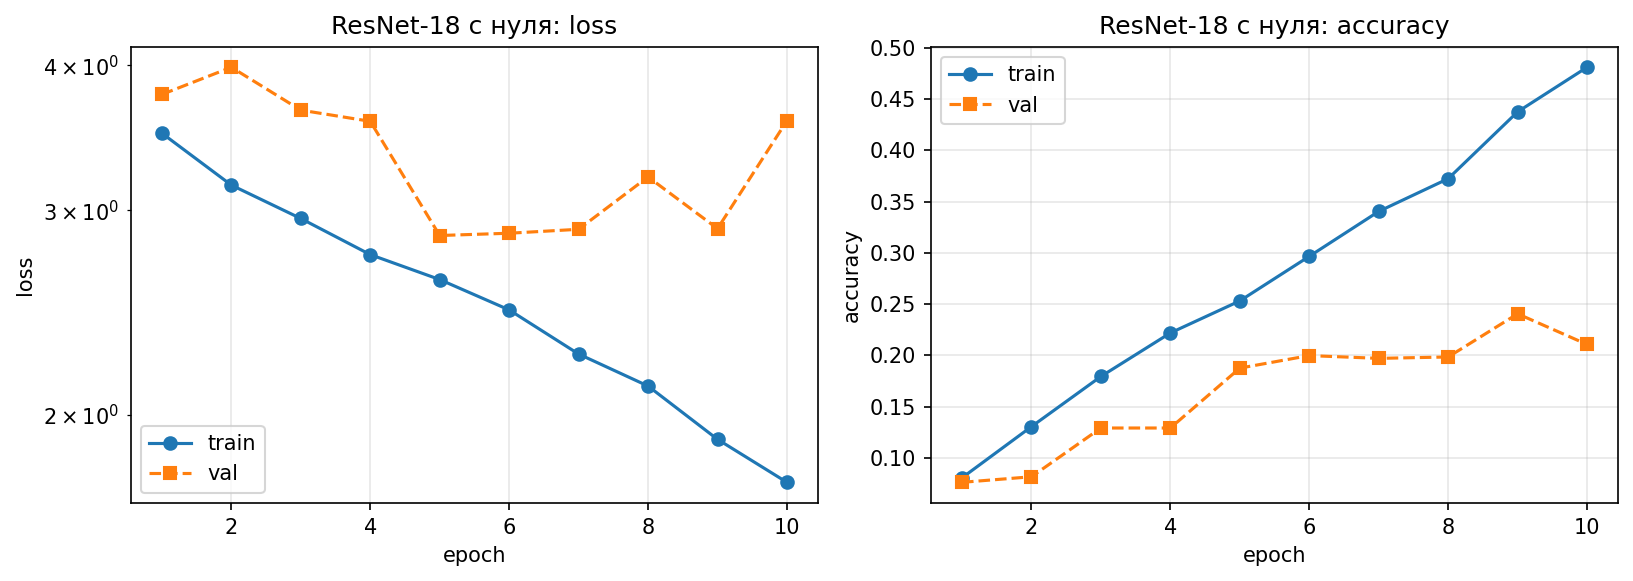

saved: ..\images\mobilenet_scratch_history.png


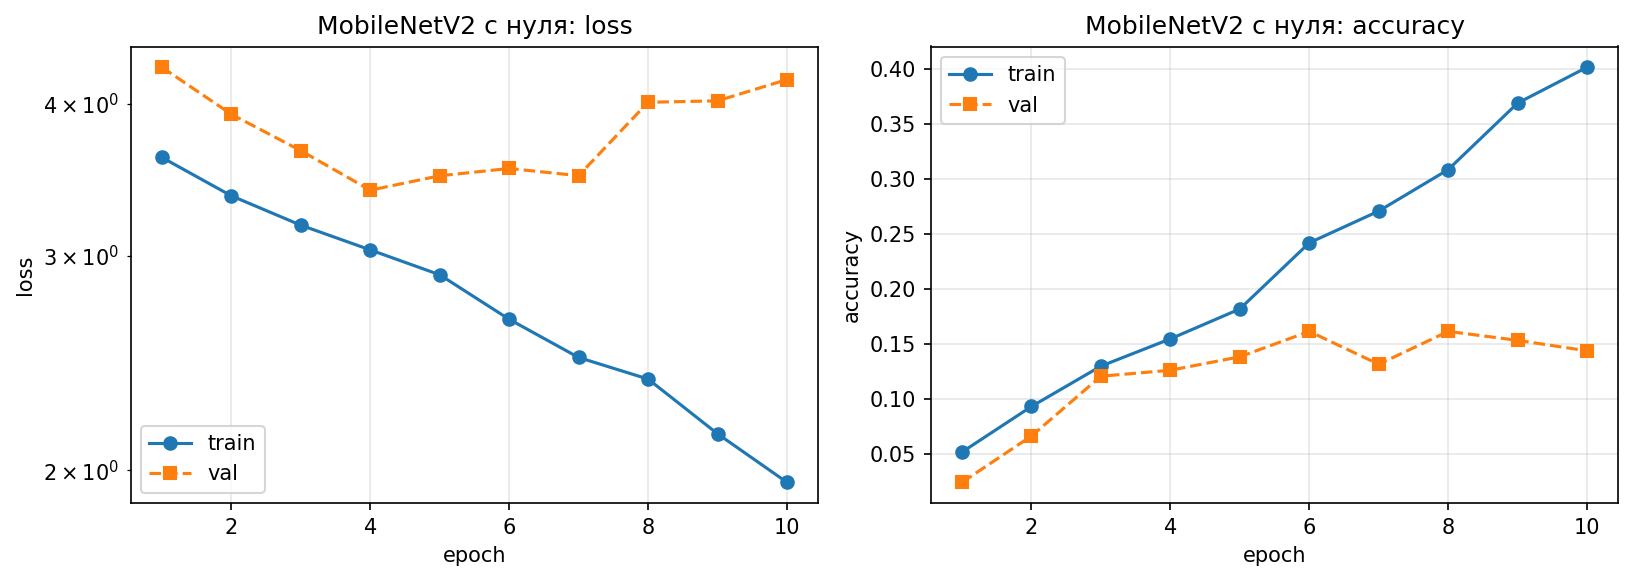

In [20]:
plot_step_histories(
    results_scratch,
    {"ResNet-18": "ResNet-18 с нуля", "MobileNetV2": "MobileNetV2 с нуля"},
    "scratch",
)

## Выходы сети как признаки для классической модели

Самый простой «перенос знаний» - комбинация готовой сети и какой-то классической: предобученная сеть — готовый экстрактор признаков. Для изображений это может быть не слишком удобно, но для определенных задач (напрмиер кластеризации) и текстов это более очевидный прием (и  некоторые его уже пытались использовать в прошлом году).

Отрежем классификатор (`fc -> nn.Identity()` у ResNet-18, `classifier -> nn.Identity()`
у MobileNetV2) и достанем эмбеддинги для всех картинок: 512-мерные у ResNet-18 и
1280-мерные у MobileNetV2. Почему мы оставляем именно эмбеддинги, а не логиты - нам важно получить именно векторы представления для каждого объекта. Поэтому выходы с пулинга нам подходят лучше всего.

Поверх обучим классическую модель — например, логистическую регрессию. 

In [21]:
def get_backbone(name: str) -> nn.Module:
    """Предобученный бэкбон без головы: на выходе эмбеддинги (512 у ResNet-18, 1280 у MobileNetV2)."""
    model = ARCHITECTURES[name](weights=IMAGENET_WEIGHTS[name])
    if name == "ResNet-18":
        model.fc = nn.Identity()
    else:
        model.classifier = nn.Identity()
    return model.to(device).eval()  # инференс: BN по running-статистикам, эмбеддинг не зависит от соседей по батчу


@torch.no_grad()
def extract_features(model, loader, device):
    # прогоняем даталоадер через сеть и копим пары (эмбеддинг, метка)
    features, targets = [], []
    for inputs, labels in tqdm.auto.tqdm(loader, leave=False, desc="features", disable=None):
        embeddings = model(inputs.to(device))  # (batch_size, feature_dim)
        features.append(embeddings.cpu().numpy())  # sklearn живёт на CPU
        targets.append(labels.numpy())
    return np.concatenate(features), np.concatenate(targets)


features_data = {}
for name in ARCHITECTURES:
    backbone = get_backbone(name)
    t_start = time.perf_counter()
    X_train, y_train = extract_features(backbone, train_loader, device) # фичи переиспользуем
    X_val, y_val = extract_features(backbone, val_loader, device)
    extract_s = time.perf_counter() - t_start
    features_data[name] = {"X_train": X_train, "y_train": y_train, "X_val": X_val, "y_val": y_val}
    print(f"{name}: X_train {X_train.shape}, X_val {X_val.shape}, извлечение заняло {extract_s:.1f} c")

ResNet-18: X_train (2944, 512), X_val (736, 512), извлечение заняло 48.7 c


MobileNetV2: X_train (2944, 1280), X_val (736, 1280), извлечение заняло 47.2 c


In [22]:
from sklearn.linear_model import LogisticRegression

for name, data in features_data.items():
    t_start = time.perf_counter()
    logreg = LogisticRegression(max_iter=2000).fit(data["X_train"], data["y_train"])
    fit_s = time.perf_counter() - t_start
    accuracy = logreg.score(data["X_val"], data["y_val"])
    print(f"{name}: LogisticRegression на {FEATURE_DIMS[name]} фичах -- "
          f"accuracy = {accuracy:.4f} (обучение заняло {fit_s:.1f} c)")

ResNet-18: LogisticRegression на 512 фичах -- accuracy = 0.9144 (обучение заняло 0.6 c)


MobileNetV2: LogisticRegression на 1280 фичах -- accuracy = 0.9280 (обучение заняло 0.5 c)


Ни одного обученного свёрточного фильтра — а качество уже заметно лучше, чем у сетей,
обученных с нуля. Значит, вся «магия» — в признаках, которые бэкбоны выучили на ImageNet;
классификатор сверху может быть совсем простым. Сравните заодно два бэкбона: у MobileNetV2
эмбеддинги в 2.5 раза длиннее (1280 против 512), при этом сама сеть примерно в 5 раз легче —
как это отражается на качестве и времени извлечения признаков, видно из вывода выше.

Минус такого подхода в том, что модель нельзя обучить на гпу, а еще он в любом случае требует двух этапов обучения. Мы же можем использовать мощности торча, чтобы ускорить обработку датасета и не собирать пайплайн из нескольких библиотек.

*Задание*: попробуйте другие классификаторы из sklearn (`SVC`, `RandomForestClassifier`,
`KNeighborsClassifier`). Затем уменьшайте обучающую выборку: при каком размере логистическая
регрессия всё ещё даёт приличное качество?

**Ответ.** Извлечение признаков заняло 48.7 с у ResNet-18 и 47.2 с у MobileNetV2, хотя эмбеддинг MobileNet длиннее: 1280 против 512. На val:

| Классификатор | ResNet-18 | MobileNetV2 |
|---|---|---|
| LogisticRegression | 0.914 | 0.928 |
| SVC, linear | 0.920 | 0.923 |
| RandomForest | 0.885 | 0.902 |
| KNN-5 | 0.872 | 0.895 |

Лучший линейный классификатор на этих признаках — SVC у ResNet-18 (0.920) и логистическая регрессия у MobileNetV2 (0.928). Оба сильно выше обучения с нуля.

Приличное качество логистической регрессии здесь — accuracy не ниже 0.8 и не дальше 0.08 от результата на всех 2944 примерах. Этот порог достигается примерно с 400 примеров: ResNet-18 0.860 при полной выборке 0.914, MobileNetV2 0.857 при полной 0.928. На 200 примерах обе модели ещё около 0.75–0.77.


In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

classifiers = {
    "SVC linear": lambda: SVC(kernel="linear", C=1.0),
    "RandomForest": lambda: RandomForestClassifier(n_estimators=100, random_state=0),
    "KNN-5": lambda: KNeighborsClassifier(n_neighbors=5),
}

for name, data in features_data.items():
    print(f"\n{name}")
    for clf_name, factory in classifiers.items():
        t_start = time.perf_counter()
        clf = factory()
        clf.fit(data["X_train"], data["y_train"])
        accuracy = clf.score(data["X_val"], data["y_val"])
        print(f"  {clf_name:16s} accuracy {accuracy:.4f}  ({time.perf_counter() - t_start:.1f} c)")

print("\nLogisticRegression, меньше обучающих примеров")
for name, data in features_data.items():
    rng = np.random.default_rng(0)
    order = rng.permutation(len(data["y_train"]))
    full_acc = LogisticRegression(max_iter=2000).fit(data["X_train"], data["y_train"]).score(data["X_val"], data["y_val"])
    print(f"{name}: вся выборка {len(data['y_train'])} -> {full_acc:.3f}")
    decent_from = None
    for n_samples in (50, 100, 200, 400, 800, 1600):
        idx = order[:n_samples]
        acc = LogisticRegression(max_iter=2000).fit(
            data["X_train"][idx], data["y_train"][idx]
        ).score(data["X_val"], data["y_val"])
        # «прилично» — не ниже 0.8 и не дальше 0.08 от результата на всех данных
        mark = ""
        if decent_from is None and acc >= 0.8 and acc >= full_acc - 0.08:
            decent_from = n_samples
            mark = "  <- ещё держится"
        print(f"  n={n_samples:4d}  accuracy {acc:.3f}{mark}")
    if decent_from is None:
        print("  до 1600 примеров порог 0.8 и отставание не больше 0.08 не достигнуты")
    else:
        print(f"  приличное качество начинается примерно с {decent_from} примеров")



ResNet-18


  SVC linear       accuracy 0.9198  (0.3 c)


  RandomForest     accuracy 0.8845  (5.6 c)


  KNN-5            accuracy 0.8723  (1.8 c)

MobileNetV2


  SVC linear       accuracy 0.9226  (1.0 c)


...

  n=1600  accuracy 0.889
  приличное качество начинается примерно с 400 примеров


MobileNetV2: вся выборка 2944 -> 0.928
  n=  50  accuracy 0.467


  n= 100  accuracy 0.686
  n= 200  accuracy 0.765


  n= 400  accuracy 0.857  <- ещё держится
  n= 800  accuracy 0.895


  n=1600  accuracy 0.918
  приличное качество начинается примерно с 400 примеров


## Обучаем только голову

Хотя это по сути та же логистическая регрессия, что и в предыдущем случае, классификатор обучается вместе
с сетью end-to-end, а не поверх заранее вычисленных фич: заменяем финальный `Linear`
на новый и обучаем только его, заморозив остальные веса (`requires_grad=False`).  
Признаки остаются «ImageNet-овскими» — посмотрим, как далеко можно уехать с замороженным
backbone. 

Проверим, что градиенты будут только у головы, а модель лежит на нужном устройстве:


In [24]:
results_head = {}  # имя архитектуры -> {"model": ..., "history": ...}

for name in ARCHITECTURES:
    print(f"\n=== {name}: обучаем только голову ===")
    seed_everything(123)
    model = get_model(name, num_classes, pretrained=True, freeze=True).to(device)
    print(f"обучаемых параметров: {count_trainable_parameters(model):,}")
    print(f"всего параметров:     {sum(p.numel() for p in model.parameters()):,}")
    head = get_head(name, model)
    print(f"градиенты только у головы: {count_trainable_parameters(model) == sum(p.numel() for p in head.parameters())}")

    # в оптимизатор передаём только обучаемые параметры: замороженные Adam не трогает,
    # но state оптимизатора не раздувается и мы контролируем ситуацию
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-3)
    history = train(
        model, train_loader, val_loader, criterion, accuracy_metric, optimizer, device,
        epochs=10, label=f"шаг 2: голова -- {name}",
    )
    results_head[name] = {"model": model, "history": history}

report_inference_time(results_head, "шаг 2: голова")


=== ResNet-18: обучаем только голову ===
обучаемых параметров: 18,981
всего параметров:     11,195,493
градиенты только у головы: True
Epoch 1/10


  train loss=2.4623 | val loss=1.4407  | val accuracy=0.7378
Epoch 2/10


  train loss=1.0342 | val loss=0.8194  | val accuracy=0.8410
Epoch 3/10


  train loss=0.6567 | val loss=0.6150  | val accuracy=0.8655
Epoch 4/10


  train loss=0.5016 | val loss=0.5382  | val accuracy=0.8709
Epoch 5/10


...

  train loss=0.3626 | val loss=0.5306  | val accuracy=0.8736
Epoch 9/10


  train loss=0.3190 | val loss=0.5159  | val accuracy=0.8723
Epoch 10/10


  train loss=0.2924 | val loss=0.4869  | val accuracy=0.8804
обучение заняло 514.0 c (51.4 c/эпоху)


шаг 2: голова -- ResNet-18: инференс val_loader -- 9.88 c (75 картинок/с)


шаг 2: голова -- MobileNetV2: инференс val_loader -- 8.70 c (85 картинок/с)


saved: ..\images\head_history.png


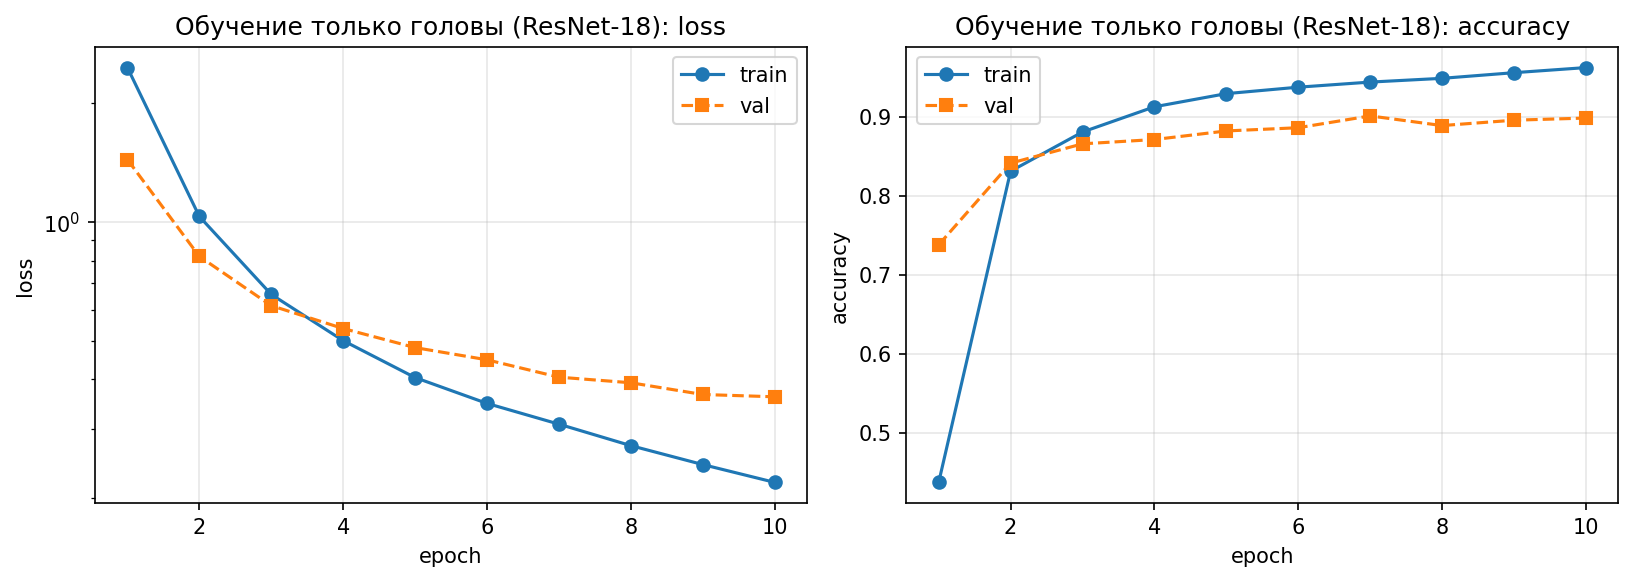

saved: ..\images\mobilenet_head_history.png

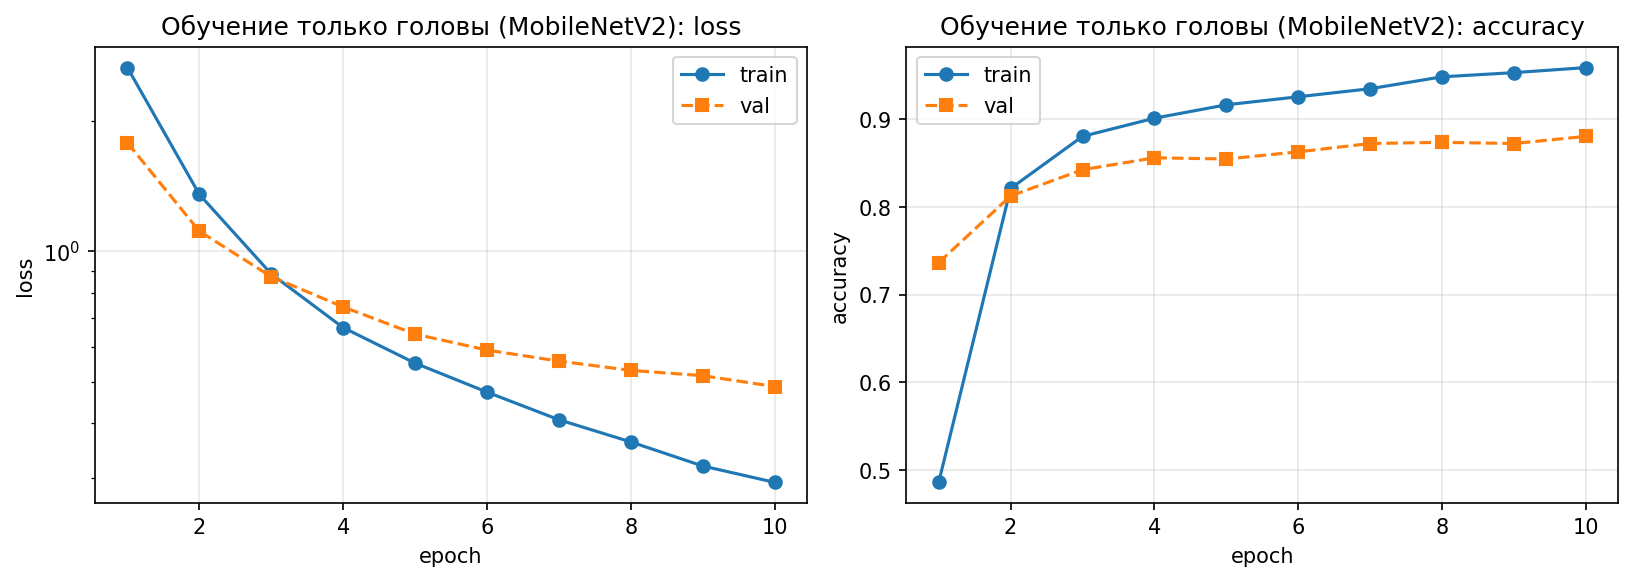

In [25]:
plot_step_histories(
    results_head,
    {"ResNet-18": "Обучение только головы (ResNet-18)", "MobileNetV2": "Обучение только головы (MobileNetV2)"},
    "head",
)

## Полный файнтюн — без аугментаций

Голова из шага 2 упёрлась в качество замороженных признаков (0.90 у ResNet-18). Разморозим
всю сеть и продолжим обучение с (а) уже обученной головой из шага 2, (б) **маленьким** lr —
если резко двинуть все веса, модель «забудет» полезные признаки, выученные на ImageNet,
(в) AdamW с weight decay.

Аугментации пока намеренно не включаем: интересно посмотреть, что будет, когда все
параметры обучаются на 3k картинках «как есть». На следующем шаге добавим аугментации
при прочих равных и отдельно посмотрим на их эффект.

In [26]:
results_finetune_noaug = {}

for name, result in results_head.items():
    print(f"\n=== {name}: полный файнтюн без аугментаций ===")
    model = copy.deepcopy(result["model"]).to(device)  # стартуем с модели шага 2, оригинал не трогаем
    for param in model.parameters():
        param.requires_grad = True  # разморозка: теперь обучаются все параметры
    print(f"обучаемых параметров: {count_trainable_parameters(model):,}")

    seed_everything(123)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=1e-4)  # lr в ~30 раз меньше, чем у головы
    # к концу обучения уменьшим lr -- так модель аккуратнее "дошлифует" веса
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[8], gamma=0.1)
    history = train(
        model, train_loader, val_loader, criterion, accuracy_metric, optimizer, device,
        epochs=10, scheduler=scheduler, label=f"шаг 3: файнтюн без аугм. -- {name}",
    )
    results_finetune_noaug[name] = {"model": model, "history": history}

report_inference_time(results_finetune_noaug, "файнтюн без аугм.")


=== ResNet-18: полный файнтюн без аугментаций ===
обучаемых параметров: 11,195,493
Epoch 1/10


  train loss=0.1887 | val loss=0.2883  | val accuracy=0.9117
Epoch 2/10


  train loss=0.0734 | val loss=0.2771  | val accuracy=0.9144
Epoch 3/10


  train loss=0.0428 | val loss=0.2640  | val accuracy=0.9158
Epoch 4/10


  train loss=0.0301 | val loss=0.2591  | val accuracy=0.9171
Epoch 5/10


...

  train loss=0.0551 | val loss=0.3130  | val accuracy=0.9144
Epoch 9/10


  train loss=0.0475 | val loss=0.3107  | val accuracy=0.9130
Epoch 10/10


  train loss=0.0478 | val loss=0.3072  | val accuracy=0.9117
обучение заняло 1211.2 c (121.1 c/эпоху)


файнтюн без аугм. -- ResNet-18: инференс val_loader -- 10.49 c (70 картинок/с)


файнтюн без аугм. -- MobileNetV2: инференс val_loader -- 8.87 c (83 картинок/с)


saved: ..\images\finetune_noaug_history.png


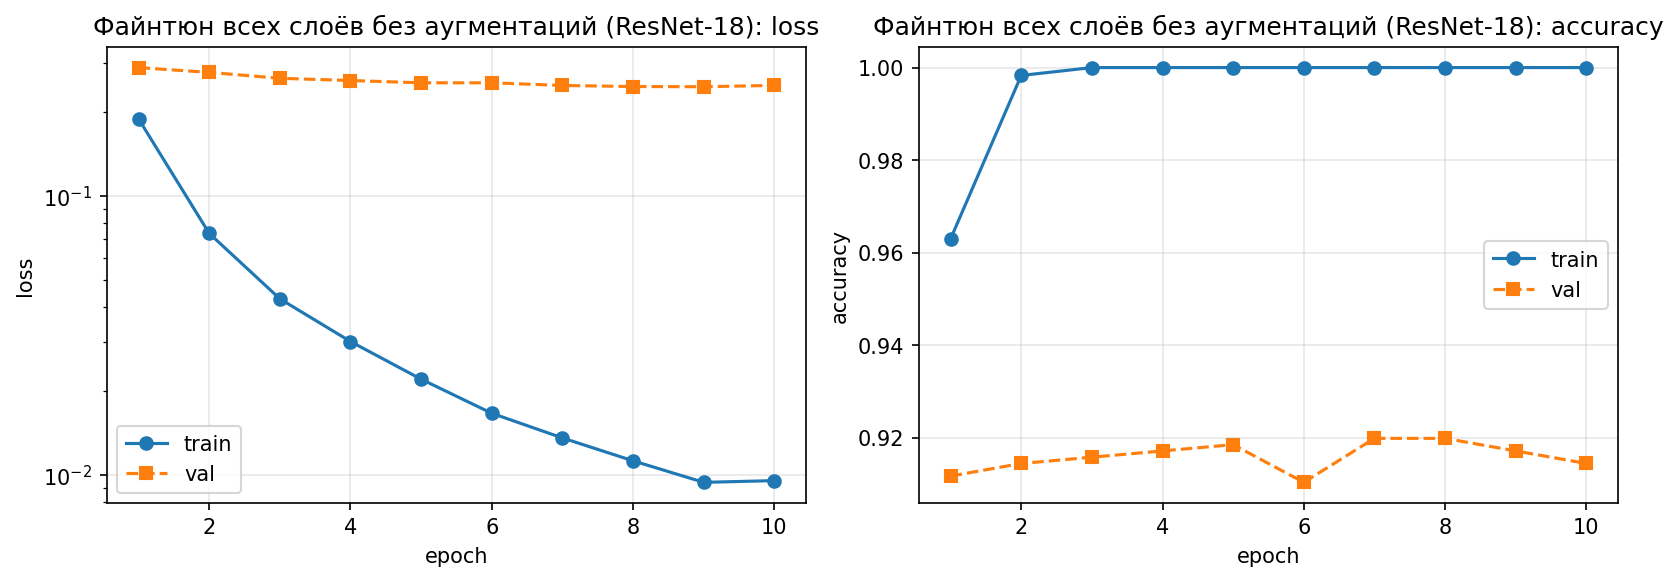

saved: ..\images\mobilenet_finetune_noaug_history.png

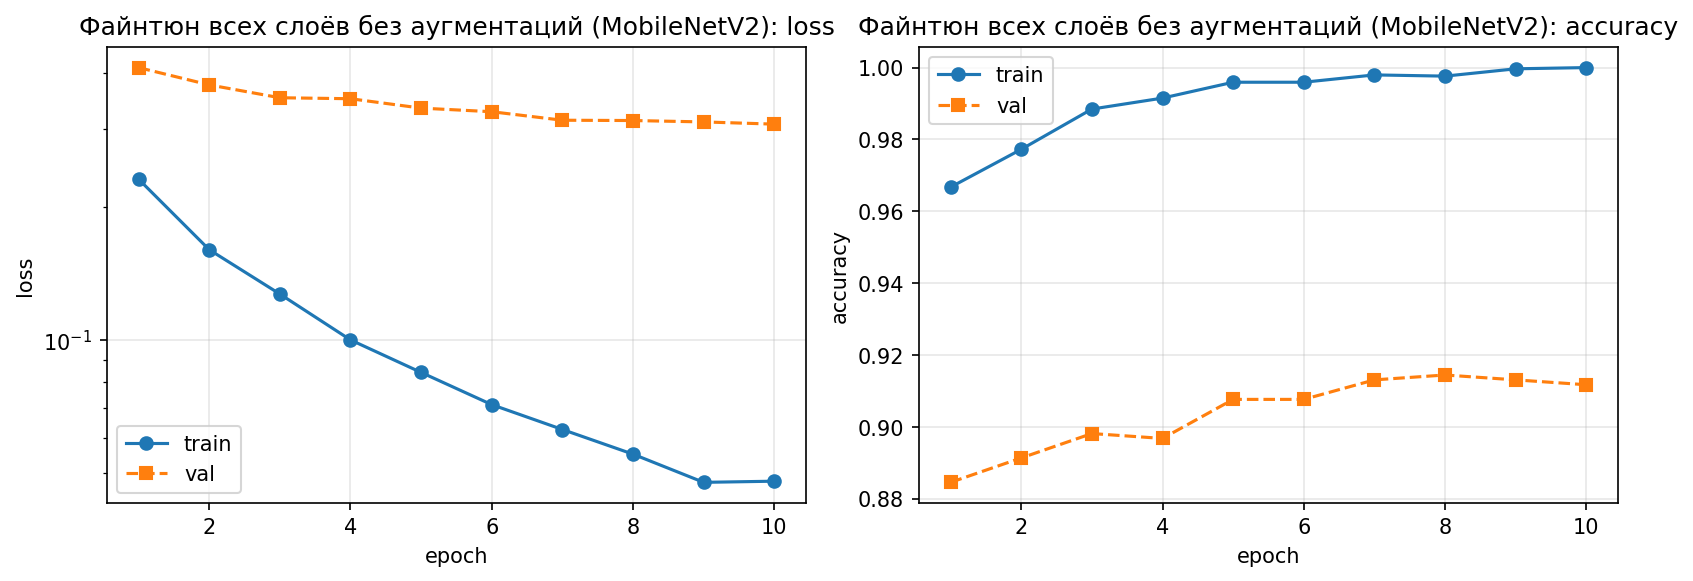

In [27]:
plot_step_histories(
    results_finetune_noaug,
    {"ResNet-18": "Файнтюн всех слоёв без аугментаций (ResNet-18)", "MobileNetV2": "Файнтюн всех слоёв без аугментаций (MobileNetV2)"},
    "finetune_noaug",
)

## Аугментации

На шаге 3 видна классическая картина переобучения: train loss упал почти до нуля, а val
loss давно вышел на плато. Поэтому нам стоит усилить борьбу с переобучением. Как? Генерировать «новые» данные из имеющихся: случайные отражения, повороты, кропы и цветовые искажения не меняют класс,
но заставляют сеть выучивать инвариантные признаки.

Типичный набор для нашей задачи:
- `ColorJitter` — случайные изменения яркости/контраста/насыщенности/оттенка;
- `RandomRotation` — небольшие повороты;
- `RandomResizedCrop` — случайный кроп с изменением масштаба (содержание то же, пиксели другие);
- `RandomHorizontalFlip` — отражение по горизонтали.

Правила:
1. Аугментации делаются только на train. Валидация и тест всегда идут через детерминированный
   пайплайн (только Resize, Normalize, CenterCrop итп).
2. Аугментация не должна слишком сильно менять данные: для пород питомцев горизонтальный флип безопасен,
   а для распознавания цифр или букв — уже нет.
3. Необязательно начинать с аггрессивных аугментаций - лучше добавлять их по 1 и с небольшой вероятностью. 


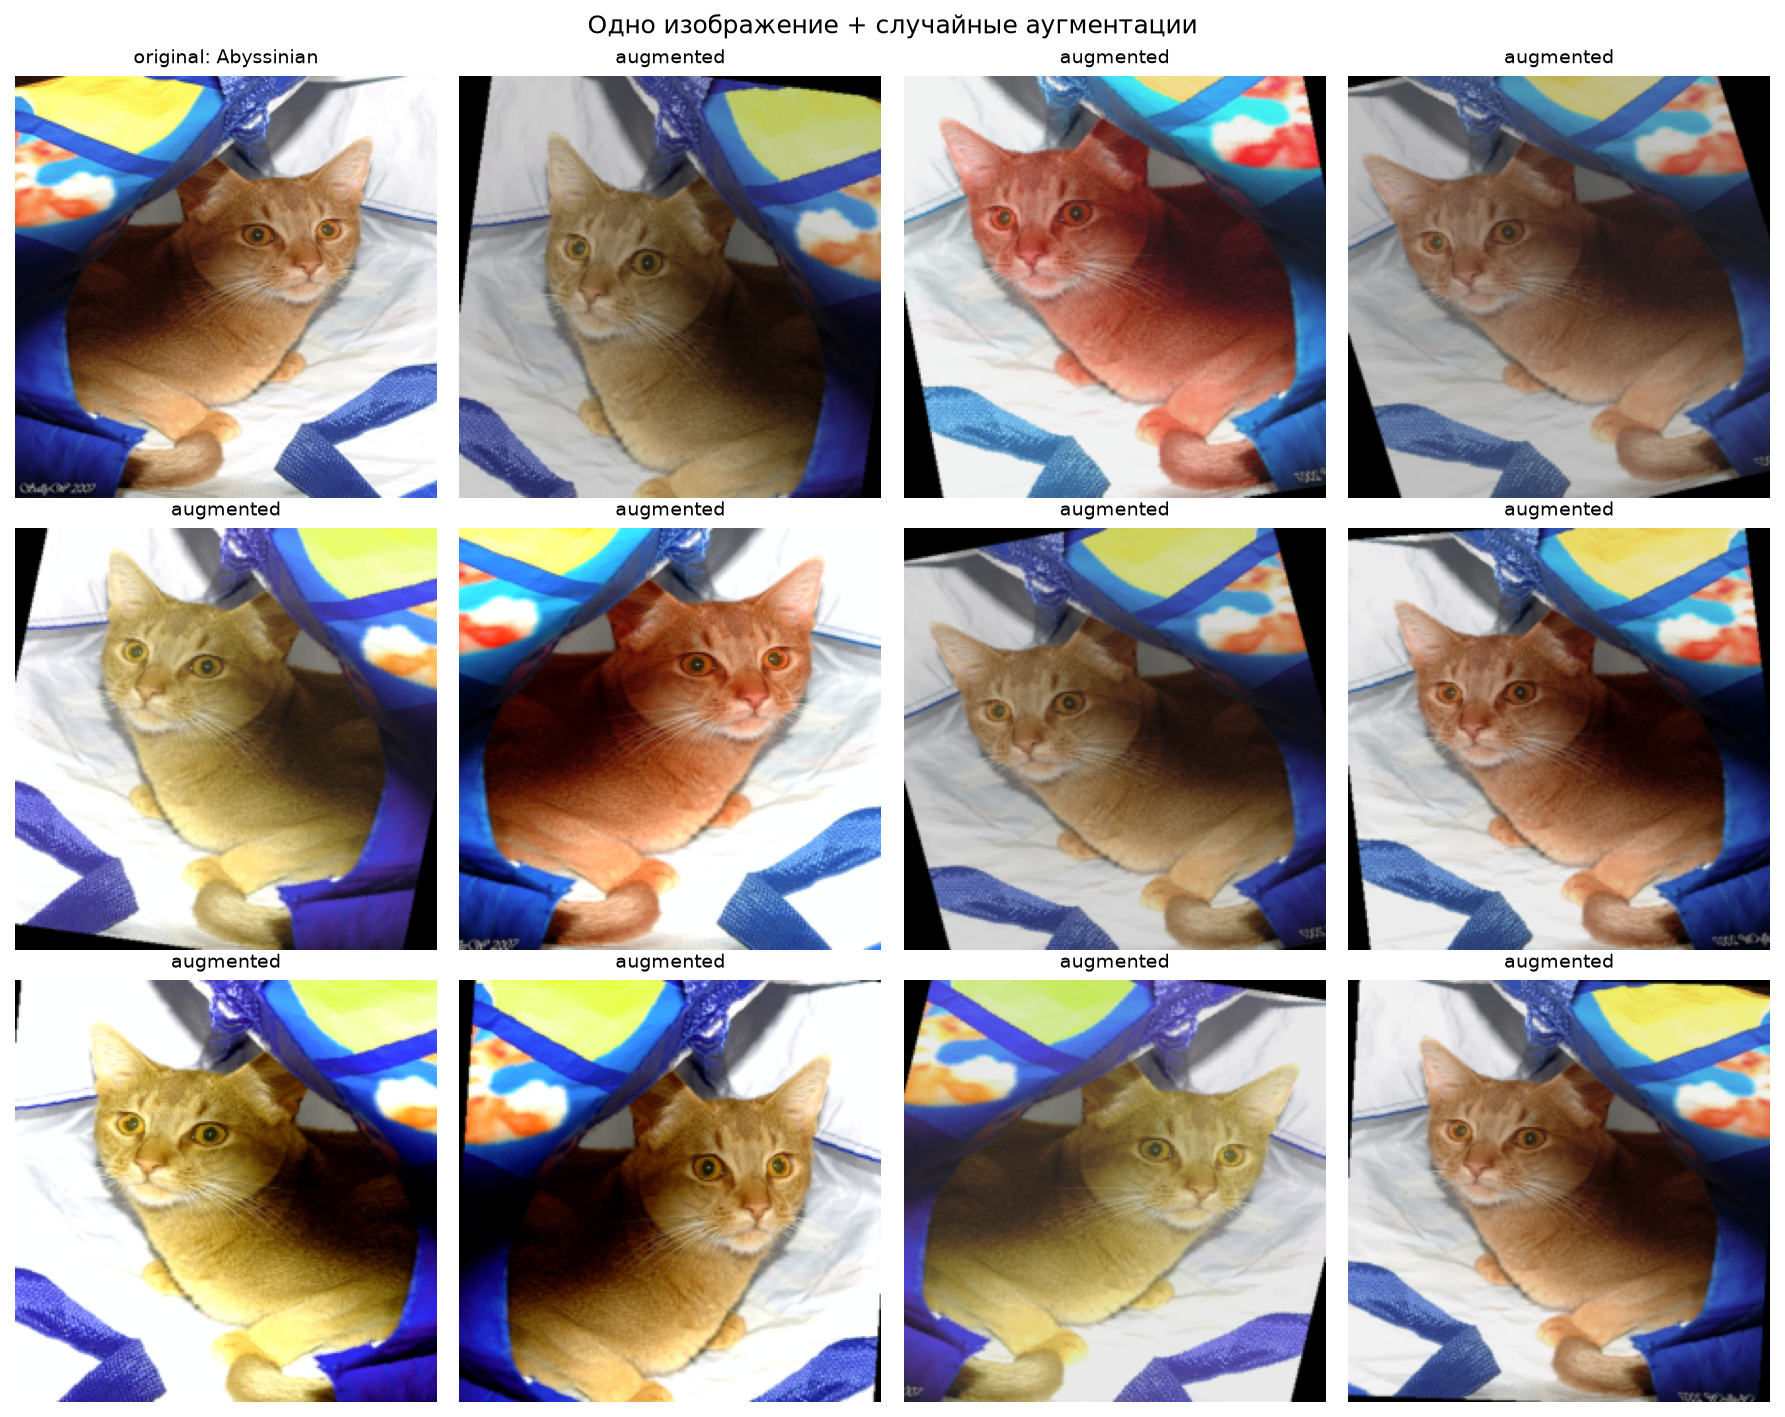

In [28]:
from utils.data import augmented_transform

# соберём новый обучающий даталоадер с аугментациями (валидация остаётся честной)
train_loader_aug, _, _, _, _ = make_dataloaders(batch_size=64, train_transform=augmented_transform)

display(Image(filename="../images/augmentations.png"))


## Обучаем только голову — с аугментациями

Прежде чем включать аугментации в полный файнтюн, ответим на более простой вопрос:
помогут ли они там, где обучается только голова? 

In [29]:
results_head_aug = {}

for name in ARCHITECTURES:
    print(f"\n=== {name}: голова с аугментациями ===")
    seed_everything(123)
    model = get_model(name, num_classes, pretrained=True, freeze=True).to(device)
    optimizer = torch.optim.Adam(  # настройки -- один в один как в шаге 2
        [p for p in model.parameters() if p.requires_grad],
        lr=1e-3,
    )
    history = train(
        model, train_loader_aug, val_loader, criterion, accuracy_metric, optimizer, device,
        epochs=10, label=f"шаг 4: голова + аугм. -- {name}",  # отличие от шага 2 -- только даталоадер
    )
    results_head_aug[name] = {"model": model, "history": history}

report_inference_time(results_head_aug, "шаг 4: голова + аугм.")


=== ResNet-18: голова с аугментациями ===
Epoch 1/10


  train loss=2.5801 | val loss=1.5148  | val accuracy=0.7201
Epoch 2/10


  train loss=1.2009 | val loss=0.8532  | val accuracy=0.8519
Epoch 3/10


  train loss=0.7826 | val loss=0.6430  | val accuracy=0.8587
Epoch 4/10


  train loss=0.6237 | val loss=0.5602  | val accuracy=0.8573
Epoch 5/10


...

  train loss=0.4475 | val loss=0.4915  | val accuracy=0.8899
Epoch 9/10


  train loss=0.4052 | val loss=0.4724  | val accuracy=0.8845
Epoch 10/10


  train loss=0.3853 | val loss=0.4527  | val accuracy=0.8913
обучение заняло 781.2 c (78.1 c/эпоху)


шаг 4: голова + аугм. -- ResNet-18: инференс val_loader -- 9.65 c (76 картинок/с)


шаг 4: голова + аугм. -- MobileNetV2: инференс val_loader -- 8.11 c (91 картинок/с)


saved: ..\images\head_aug_history.png


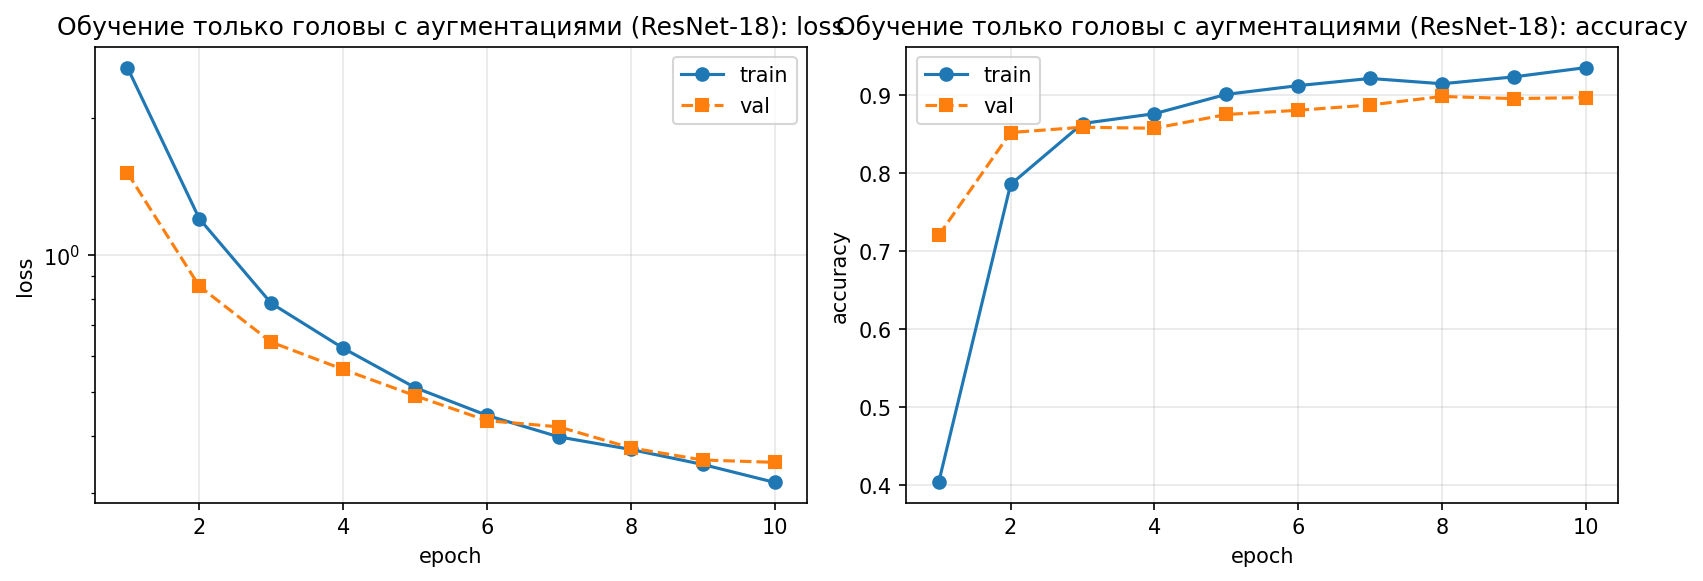

saved: ..\images\mobilenet_head_aug_history.png

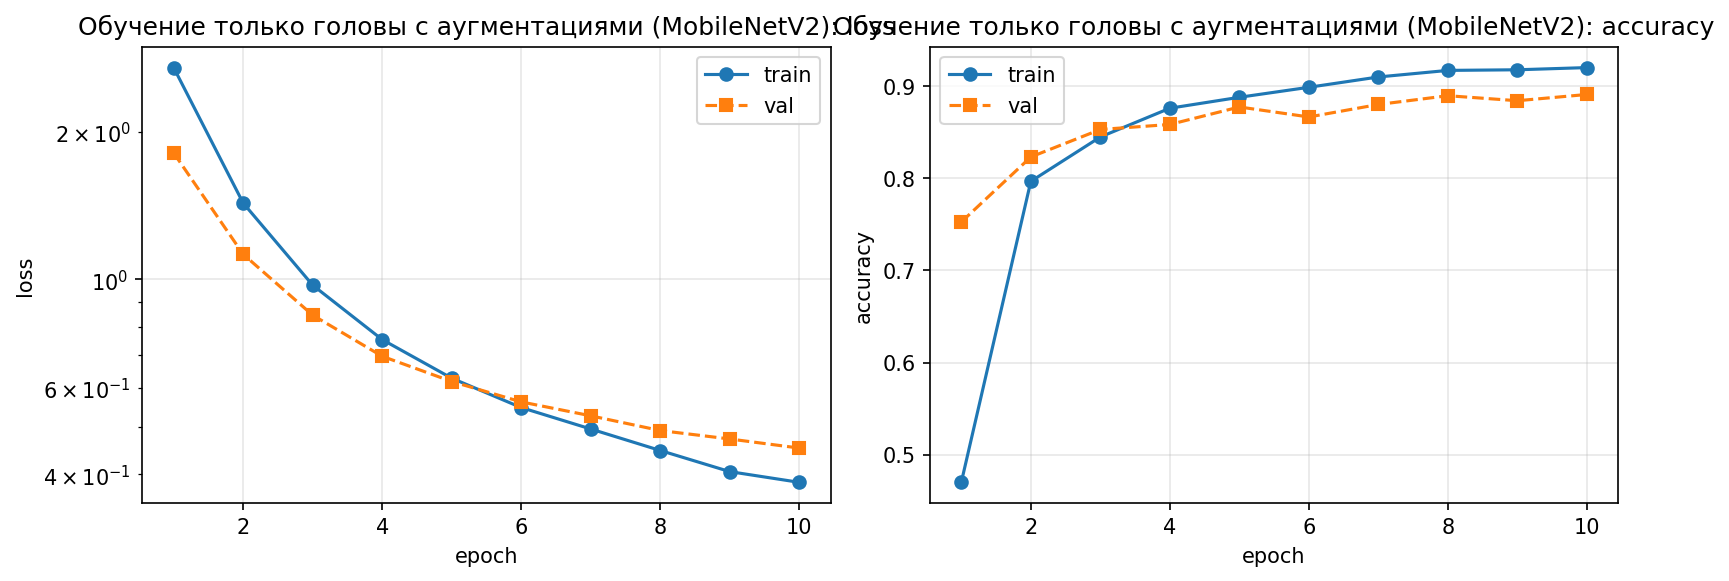

In [30]:
plot_step_histories(
    results_head_aug,
    {"ResNet-18": "Обучение только головы с аугментациями (ResNet-18)", "MobileNetV2": "Обучение только головы с аугментациями (MobileNetV2)"},
    "head_aug",
)

## Полный файнтюн — с аугментациями

Финальный уровень файнтюнинга: повторим шаг 3, но включим аугментации. 

In [31]:
results_finetune_aug = {}

for name, result in results_head.items():
    print(f"\n=== {name}: полный файнтюн с аугментациями ===")
    model = copy.deepcopy(result["model"]).to(device)  # как в шаге 3: старт с головы из шага 2
    for param in model.parameters():
        param.requires_grad = True
    print(f"обучаемых параметров: {count_trainable_parameters(model):,}")

    seed_everything(123)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=1e-4)  # как в шаге 3
    # к концу обучения уменьшим lr -- так модель аккуратнее "дошлифует" веса
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[8], gamma=0.1)
    history = train(
        model, train_loader_aug, val_loader, criterion, accuracy_metric, optimizer, device,
        epochs=10, scheduler=scheduler, label=f"шаг 5: файнтюн + аугм. -- {name}",  # единственное отличие от шага 3 -- аугментации
    )
    results_finetune_aug[name] = {"model": model, "history": history}

report_inference_time(results_finetune_aug, "шаг 5: файнтюн + аугм.")


=== ResNet-18: полный файнтюн с аугментациями ===
обучаемых параметров: 11,195,493
Epoch 1/10


  train loss=0.3011 | val loss=0.2756  | val accuracy=0.9198
Epoch 2/10


  train loss=0.1870 | val loss=0.2611  | val accuracy=0.9185
Epoch 3/10


  train loss=0.1498 | val loss=0.2522  | val accuracy=0.9198
Epoch 4/10


  train loss=0.1231 | val loss=0.2472  | val accuracy=0.9226
Epoch 5/10


...

  train loss=0.1516 | val loss=0.2768  | val accuracy=0.9171
Epoch 9/10


  train loss=0.1380 | val loss=0.2750  | val accuracy=0.9171
Epoch 10/10


  train loss=0.1434 | val loss=0.2786  | val accuracy=0.9144
обучение заняло 1818.0 c (181.8 c/эпоху)


шаг 5: файнтюн + аугм. -- ResNet-18: инференс val_loader -- 9.83 c (75 картинок/с)


шаг 5: файнтюн + аугм. -- MobileNetV2: инференс val_loader -- 8.45 c (87 картинок/с)


saved: ..\images\finetune_history.png


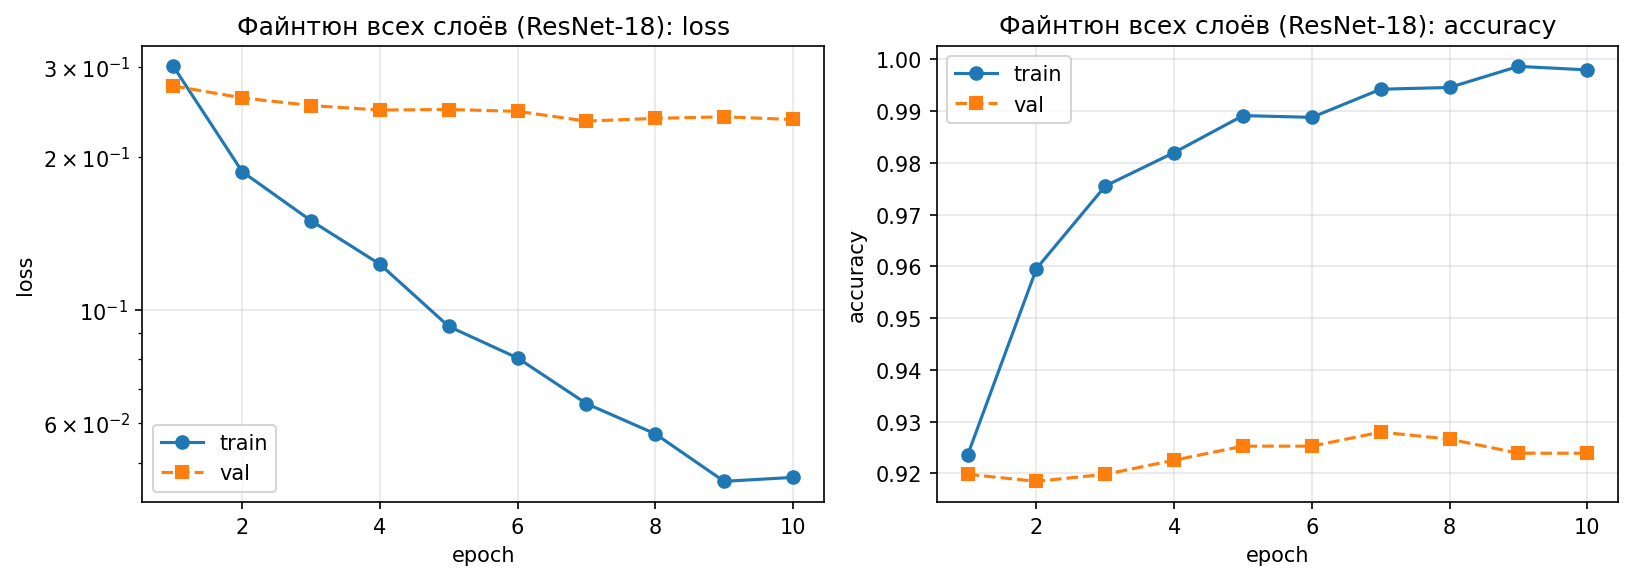

saved: ..\images\mobilenet_finetune_history.png

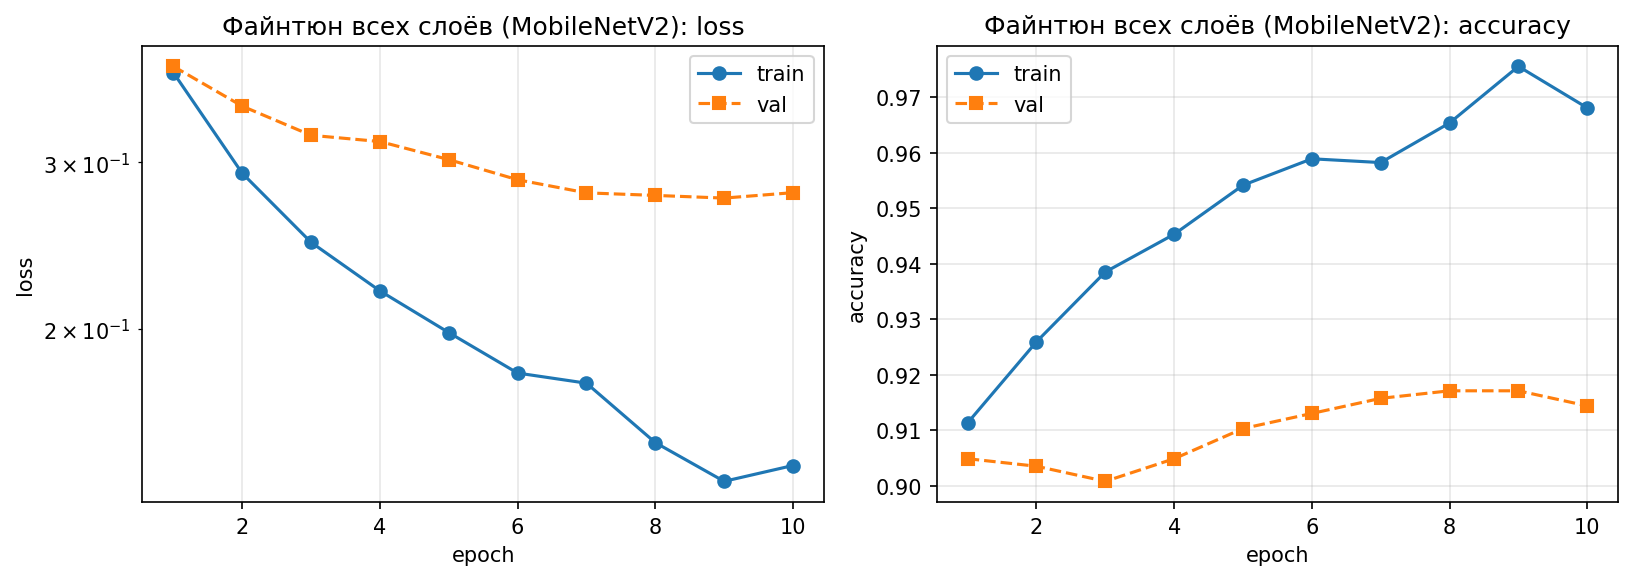

In [32]:
plot_step_histories(
    results_finetune_aug,
    {"ResNet-18": "Файнтюн всех слоёв (ResNet-18)", "MobileNetV2": "Файнтюн всех слоёв (MobileNetV2)"},
    "finetune",
)

In [33]:
# финальная оценка лучших моделей: не только accuracy, но и precision/recall по классам
final_metrics = {}
for name, result in results_finetune_aug.items():
    final_metrics[name] = validate(result["model"], val_loader, criterion, full_metric, device)
    print(f"{name}: " + ", ".join(f"{key}={value:.4f}" for key, value in final_metrics[name].items()))
final_metrics

ResNet-18: loss=0.2368, accuracy=0.9239, precision_macro=0.9307, precision_micro=0.9239, recall_macro=0.9245, recall_micro=0.9239


MobileNetV2: loss=0.2786, accuracy=0.9144, precision_macro=0.9204, precision_micro=0.9144, recall_macro=0.9175, recall_micro=0.9144


{'ResNet-18': {'loss': 0.23680850553015867,
  'accuracy': 0.9239130616188049,
  'precision_macro': 0.9306967854499817,
  'precision_micro': 0.9239130616188049,
  'recall_macro': 0.9244838953018188,
  'recall_micro': 0.9239130616188049},
 'MobileNetV2': {'loss': 0.27863332877556485,
  'accuracy': 0.914402186870575,
  'precision_macro': 0.9204199314117432,
  'precision_micro': 0.914402186870575,
  'recall_macro': 0.9175476431846619,
  'recall_micro': 0.914402186870575}}

## Сравнение стратегий

Числа ниже — лучшая val accuracy за 10 эпох на этом CPU-прогоне. Для строки «фичи + LogReg» это accuracy логистической регрессии на val, без кривой по эпохам.

| Стратегия | Что обучаем | ResNet-18 | MobileNetV2 |
|---|---|---|---|
| с нуля (Adam) | вся сеть | 0.240 | 0.162 |
| фичи + LogReg | ничего | 0.914 | 0.928 |
| только голова (Adam) | `fc` (19k) / `classifier[1]` (47k) | 0.901 | 0.880 |
| только голова (Adam + аугм.) | `fc` (19k) / `classifier[1]` (47k) | 0.898 | 0.891 |
| полный файнтюн (AdamW, без аугм.) | вся сеть | 0.920 | 0.914 |
| полный файнтюн (AdamW + аугм.) | вся сеть | 0.928 | 0.917 |

На последней эпохе файнтюна с аугментациями macro precision / macro recall: ResNet-18 0.931 / 0.924, MobileNetV2 0.920 / 0.918. Micro-версии совпадают с accuracy этой эпохи (0.924 и 0.914): у одной метки на картинку micro — это та же доля верных ответов.

- Обучение с нуля на 3k картинок за 10 эпох дошло до 0.240 у ResNet-18 и 0.162 у MobileNetV2. Train loss падал, а val loss к концу снова вырос: маленькой выборки не хватает, чтобы с нуля выучить признаки.
- Фичи + LogReg считаются за доли секунды: 0.914 на ResNet-18 и 0.928 на MobileNetV2. Признаки ImageNet уже почти линейно разделимы. Полный файнтюн ResNet-18 поднимается до 0.928. У MobileNetV2 логистическая регрессия на замороженных признаках остаётся выше файнтюна (0.928 против 0.917).
- Рецепт не привязан к архитектуре: одна и та же двухэтапная схема (голова, затем вся сеть) работает на обоих бэкбонах. Меняется механика замены головы: `classifier[1]` вместо `fc`.
- Лёгкий бэкбон (2.3M параметров против 11.2M у ResNet-18) на обучении чуть ниже: файнтюн с аугментациями 0.917 против 0.928. На замороженных признаках он наоборот выше. Инференс val на CPU у MobileNetV2 быстрее, около 85–90 картинок/с против примерно 75 у ResNet-18. Больший lr в задании 4 поднимает MobileNet до 0.923.
- Полный файнтюн без аугментаций обгоняет одну голову: ResNet-18 0.920 против 0.901, MobileNetV2 0.914 против 0.880. Признаки адаптируются к породам. Train loss у ResNet при этом падает к 0.01, а val loss выходит на плато.
- Аугментации на полном файнтюне добавляют немного: ResNet-18 0.928 против 0.920, MobileNetV2 0.917 против 0.914. Train loss остаётся выше, чем без аугментаций.
- Для одной головы аугментации почти ничего не двигают: ResNet-18 0.901 против 0.898, MobileNetV2 0.880 против 0.891. У линейного слоя на 19k–47k параметров мало ресурса запоминать обучающую выборку, поэтому и польза от аугментаций меньше, чем у полной сети.
- Время тоже критерий: `train()` печатает время обучения, `report_inference_time()` — скорость инференса. На GPU множество мелких depthwise-свёрток MobileNetV2 может съесть выигрыш от меньшего числа параметров. На этом CPU лёгкий бэкбон быстрее.
- ResNet = свёрточные блоки + **residual connections** (градиенты не затухают) + **BatchNorm** (стабильное обучение) + **global average pooling** (компактная голова без переобучения).
- С ростом числа обучаемых параметров уменьшаем learning rate и включаем регуляризацию: аугментации, L2 (weight decay), адаптивный оптимизатор AdamW.
- Функция потерь — удобный прибор: по ней видно и слишком большой или маленький lr, и слишком агрессивный weight decay.

*Задание 1*: попробуйте более сильные аугментации (`transforms.RandAugment`, `RandomErasing`) — помогут ли они полной сети? А одной голове?

*Задание 2*: попробуйте `resnet50` с bottleneck-блоками и сравните время/качество.

*Задание 3*: добавьте планировщик lr (`CosineAnnealingLR`, `OneCycleLR`) и сравните кривые.

*Задание 4*: «тонкие» сети часто предпочитают больший learning rate — повторите шаг 5 для MobileNetV2 с lr=3e-4 вместо 3e-5. Затем соберите `mobilenet_v2(width_mult=0.5, weights=None)` (готовых предобученных весов для него нет), обучите по той же схеме и сравните: во сколько раз меньше параметров, насколько ниже качество и быстрее инференс?


In [34]:
# сводная таблица замеров, накопленных в TIMING на всех шагах практики
header = f"{'эксперимент':38s} | {'обучение, c':>11s} | {'c/эпоху':>7s} | {'инференс, c':>11s} | {'картинок/с':>10s}"
print(header)
print("-" * len(header))
for label, row in TIMING.items():
    train_s = row.get("train_s", float("nan"))
    per_epoch = row.get("sec_per_epoch", float("nan"))
    infer_s = row.get("infer_s", float("nan"))
    ips = row.get("images_per_s", float("nan"))
    print(f"{label:38s} | {train_s:11.1f} | {per_epoch:7.1f} | {infer_s:11.2f} | {ips:10.0f}")

эксперимент                            | обучение, c | c/эпоху | инференс, c | картинок/с
-----------------------------------------------------------------------------------------
шаг 0: с нуля -- ResNet-18             |      1156.8 |   115.7 |        9.99 |         74
шаг 0: с нуля -- MobileNetV2           |      1216.4 |   121.6 |        8.83 |         83
шаг 2: голова -- ResNet-18             |       552.0 |    55.2 |        9.88 |         75
шаг 2: голова -- MobileNetV2           |       514.0 |    51.4 |        8.70 |         85
шаг 3: файнтюн без аугм. -- ResNet-18  |      1123.5 |   112.3 |       10.49 |         70
шаг 3: файнтюн без аугм. -- MobileNetV2 |      1211.2 |   121.1 |        8.87 |         83
шаг 4: голова + аугм. -- ResNet-18     |       810.5 |    81.1 |        9.65 |         76
шаг 4: голова + аугм. -- MobileNetV2   |       781.2 |    78.1 |        8.11 |         91
шаг 5: файнтюн + аугм. -- ResNet-18    |      1470.3 |   147.0 |        9.83 |         75
шаг 5: фа

## Типичные ошибки при файнтюнинге

Рассмотрим грабли, на которые наступают чаще всего.

1) Нормализация с чужими mean/std (или вовсе без него) приводит к тому, что сеть получает непривычные входы. Качество проседает на заметные 5–15%, уверенные предсказания
  становятся «размытыми». В случае, когда тюнится голова, можно вообещ не увидеть ожидаемого прогресса. 

2) Слишком большой learning rate.  В таком случае val loss взлетает на первых эпохах — модель «забывает» признаки выученные на 
  ImageNet или другом базовом датасете  (catastrophic forgetting) и становится хуже замороженного бейзлайна. Если модель была в узком минимуме, она может начать "прыгать" туда-сюда и не показывать улучшения на валидации

3) Аугментации утекли в валидацию:  val-метрики шумят от эпохи к эпохе и занижаются, сравнение
  стратегий теряет смысл. Стоит  визуализировать батч из `val_loader` —
  случайные повороты и кропы видны сразу и проверить, что transform детерминирован. При этом существует техника test-time augmentations, которая призвана оценивать устойчиовсть модели, но должна применяться с умом.


4) Утечка данных между train и val aka контаминация вам уже знакома. 


Общий принцип: сначала соберите простейший рабочий бейзлайн (шаг 1) и переобучитесь на одном батче,  большинство ошибок из этого списка видно по
кривым или паре быстрых проверок раньше, чем по итоговой метрике.


## Итоговые числа по стратегиям

Таблица в разделе «Сравнение стратегий» заполнена лучшей val accuracy этого прогона. Печать ниже повторяет пять стратегий с обучением. Строка логистической регрессии есть только в таблице: у неё нет истории по эпохам и в `TIMING` она не входит.


In [35]:
def best_val(history):
    return max(history["val_accuracy"])


strategy_rows = [
    ("с нуля", results_scratch),
    ("только голова", results_head),
    ("голова + аугментации", results_head_aug),
    ("файнтюн без аугментаций", results_finetune_noaug),
    ("файнтюн + аугментации", results_finetune_aug),
]
print(f"{'стратегия':28s} {'ResNet-18':>10s} {'MobileNetV2':>12s}")
for title, bucket in strategy_rows:
    print(f"{title:28s} {best_val(bucket['ResNet-18']['history']):10.3f} {best_val(bucket['MobileNetV2']['history']):12.3f}")


стратегия                     ResNet-18  MobileNetV2
с нуля                            0.240        0.162
только голова                     0.901        0.880
голова + аугментации              0.898        0.891
файнтюн без аугментаций           0.920        0.914
файнтюн + аугментации             0.928        0.917


## Дополнительные задания

Ниже четыре задания из конца ноутбука. Бюджет тот же, что у соответствующих шагов: 10 эпох, seed 123. Сильные аугментации, ResNet-50 и планировщики сравниваются на ResNet-18, потому что вопрос про эффект приёма, а не про второй бэкбон. Шаг с learning rate и узкой сетью — на MobileNet, как в формулировке.


### Задание 1. RandAugment и RandomErasing

Обычные аугментации шага 4–5 — это цвет, небольшой поворот, кроп и отражение. Здесь политика жёстче: `RandAugment` (2 операции, magnitude 9), кроп поагрессивнее и `RandomErasing` после нормализации. Сравниваем и голову, и полный файнтюн ResNet-18 с уже посчитанными шагами 4 и 5.

**Ответ.** Голова ResNet-18: обычные аугментации 0.898, RandAugment и RandomErasing 0.899. Полный файнтюн: 0.928 против 0.918. Жёсткая политика голове ничего не добавляет, а полной сети мешает: за 10 эпох она не добирает качество обычных аугментаций.


In [36]:
strong_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandAugment(num_ops=2, magnitude=9),
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.25),
])
train_loader_strong, _, _, _, _ = make_dataloaders(batch_size=64, train_transform=strong_transform)

seed_everything(123)
model_head_strong = get_model("ResNet-18", num_classes, pretrained=True, freeze=True).to(device)
optimizer = torch.optim.Adam([p for p in model_head_strong.parameters() if p.requires_grad], lr=1e-3)
history_head_strong = train(
    model_head_strong, train_loader_strong, val_loader, criterion, accuracy_metric, optimizer, device,
    epochs=10, label="доп 1: голова + RandAugment -- ResNet-18",
)

model_ft_strong = copy.deepcopy(results_head["ResNet-18"]["model"]).to(device)
for param in model_ft_strong.parameters():
    param.requires_grad = True
seed_everything(123)
optimizer = torch.optim.AdamW(model_ft_strong.parameters(), lr=3e-5, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[8], gamma=0.1)
history_ft_strong = train(
    model_ft_strong, train_loader_strong, val_loader, criterion, accuracy_metric, optimizer, device,
    epochs=10, scheduler=scheduler, label="доп 1: файнтюн + RandAugment -- ResNet-18",
)

head_base = best_val(results_head_aug["ResNet-18"]["history"])
ft_base = best_val(results_finetune_aug["ResNet-18"]["history"])
head_strong = best_val(history_head_strong)
ft_strong = best_val(history_ft_strong)
print(f"голова: обычные аугментации {head_base:.3f}, RandAugment+Erasing {head_strong:.3f}")
print(f"полный файнтюн: обычные {ft_base:.3f}, RandAugment+Erasing {ft_strong:.3f}")
print(
    "Сильные аугментации двигают полный файнтюн сильнее головы."
    if abs(ft_strong - ft_base) > abs(head_strong - head_base)
    else "На голове сдвиг не меньше, чем на полной сети: линейному слою лишний шум почти некуда пристроить."
)


Epoch 1/10


  train loss=2.7853 | val loss=1.6220  | val accuracy=0.6916
Epoch 2/10


  train loss=1.5360 | val loss=0.9356  | val accuracy=0.8003
Epoch 3/10


  train loss=1.1114 | val loss=0.6897  | val accuracy=0.8505
Epoch 4/10


  train loss=0.9318 | val loss=0.5573  | val accuracy=0.8560
Epoch 5/10


...

  train loss=0.2515 | val loss=0.2651  | val accuracy=0.9171
Epoch 7/10


  train loss=0.2412 | val loss=0.2673  | val accuracy=0.9144
Epoch 8/10


  train loss=0.2174 | val loss=0.2720  | val accuracy=0.9158
Epoch 9/10


  train loss=0.2090 | val loss=0.2693  | val accuracy=0.9144
Epoch 10/10


  train loss=0.2275 | val loss=0.2633  | val accuracy=0.9144
обучение заняло 1155.2 c (115.5 c/эпоху)
голова: обычные аугментации 0.898, RandAugment+Erasing 0.899
полный файнтюн: обычные 0.928, RandAugment+Erasing 0.918
Сильные аугментации двигают полный файнтюн сильнее головы.


### Задание 2. ResNet-50

Та же двухшаговая схема, что у ResNet-18: 10 эпох только голова (Adam, lr `1e-3`), затем 10 эпох всей сети на аугментациях (AdamW, lr `3e-5`, MultiStepLR). Считаем параметры, лучшую val accuracy и время.

**Ответ.** ResNet-50 содержит 23.6M параметров против 11.2M у ResNet-18. Голова дошла до 0.916, файнтюн с аугментациями — до 0.939 (у ResNet-18 файнтюн 0.928). Инференс val: 25.4 с, 29 картинок/с, против 10.0 с и 74 картинок/с у ResNet-18. Файнтюн шёл 344.8 с на эпоху против 147 с у ResNet-18.


In [37]:
from torchvision.models import ResNet50_Weights, resnet50

seed_everything(123)
resnet50_model = resnet50(weights=ResNet50_Weights.DEFAULT)
for param in resnet50_model.parameters():
    param.requires_grad = False
resnet50_model.fc = nn.Linear(resnet50_model.fc.in_features, num_classes)
resnet50_model = resnet50_model.to(device)
print(f"ResNet-50 параметров: {sum(p.numel() for p in resnet50_model.parameters()):,}")
print(f"обучаемых в голове: {count_trainable_parameters(resnet50_model):,}")

optimizer = torch.optim.Adam([p for p in resnet50_model.parameters() if p.requires_grad], lr=1e-3)
history_r50_head = train(
    resnet50_model, train_loader, val_loader, criterion, accuracy_metric, optimizer, device,
    epochs=10, label="доп 2: голова -- ResNet-50",
)

for param in resnet50_model.parameters():
    param.requires_grad = True
seed_everything(123)
optimizer = torch.optim.AdamW(resnet50_model.parameters(), lr=3e-5, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[8], gamma=0.1)
history_r50 = train(
    resnet50_model, train_loader_aug, val_loader, criterion, accuracy_metric, optimizer, device,
    epochs=10, scheduler=scheduler, label="доп 2: файнтюн + аугм. -- ResNet-50",
)
elapsed_r50, ips_r50 = measure_inference_time(resnet50_model, val_loader, device)
elapsed_r18, ips_r18 = measure_inference_time(results_finetune_aug["ResNet-18"]["model"], val_loader, device)
print(f"лучшая val accuracy: ResNet-18 {best_val(results_finetune_aug['ResNet-18']['history']):.3f}, "
      f"ResNet-50 голова {best_val(history_r50_head):.3f}, ResNet-50 файнтюн {best_val(history_r50):.3f}")
print(f"инференс val: ResNet-18 {elapsed_r18:.1f} c ({ips_r18:.0f} картинок/с), "
      f"ResNet-50 {elapsed_r50:.1f} c ({ips_r50:.0f} картинок/с)")


ResNet-50 параметров: 23,583,845
обучаемых в голове: 75,813
Epoch 1/10


  train loss=2.5092 | val loss=1.6225  | val accuracy=0.8356
Epoch 2/10


  train loss=1.0824 | val loss=0.9154  | val accuracy=0.8845
Epoch 3/10


  train loss=0.6071 | val loss=0.6617  | val accuracy=0.8913
Epoch 4/10


  train loss=0.4144 | val loss=0.5473  | val accuracy=0.8940
Epoch 5/10


...

  train loss=0.0137 | val loss=0.1823  | val accuracy=0.9348
Epoch 8/10


  train loss=0.0134 | val loss=0.1840  | val accuracy=0.9361
Epoch 9/10


  train loss=0.0096 | val loss=0.1871  | val accuracy=0.9334
Epoch 10/10


  train loss=0.0107 | val loss=0.1817  | val accuracy=0.9389
обучение заняло 3448.3 c (344.8 c/эпоху)


лучшая val accuracy: ResNet-18 0.928, ResNet-50 голова 0.916, ResNet-50 файнтюн 0.939
инференс val: ResNet-18 10.0 c (74 картинок/с), ResNet-50 25.4 c (29 картинок/с)


### Задание 3. Планировщики

`train` шагает планировщик раз за эпоху, поэтому и Cosine, и OneCycle настроены на 10 шагов, а не на число батчей. Старт тот же, что у шага 5: голова ResNet-18, AdamW, аугментации, 10 эпох. Cosine затухает от `3e-5` к нулю. OneCycle за эти 10 эпох поднимается до `3e-4` и возвращается вниз: это проверка, помогает ли более высокий пик, а не копия MultiStep.

Ячейка ниже сама обучает голову ResNet-18 и прогоняет от её копий MultiStep, Cosine и OneCycle: предыдущий процесс оборвался, и веса шага 5 в ядре не сохранились. Кривая MultiStep строится заново от этой головы, в одном прогоне с Cosine и OneCycle.

**Ответ.** Лучшая val accuracy от одной и той же головы: MultiStep 0.928, CosineAnnealing 0.925, OneCycle 0.916. У OneCycle пик lr `3e-4` на 4-й эпохе уронил accuracy до 0.845, затем выросла до 0.916. Выше остался MultiStep, 0.928.


Epoch 1/10


  train loss=2.4623 | val loss=1.4407  | val accuracy=0.7378
Epoch 2/10


  train loss=1.0342 | val loss=0.8194  | val accuracy=0.8410
Epoch 3/10


  train loss=0.6567 | val loss=0.6150  | val accuracy=0.8655
Epoch 4/10


  train loss=0.5016 | val loss=0.5382  | val accuracy=0.8709
Epoch 5/10


...

  train loss=0.0452 | val loss=0.3383  | val accuracy=0.8940
Epoch 7/10


  train loss=0.0239 | val loss=0.2975  | val accuracy=0.9090
Epoch 8/10


  train loss=0.0166 | val loss=0.3024  | val accuracy=0.9103
Epoch 9/10


  train loss=0.0105 | val loss=0.3062  | val accuracy=0.9130
Epoch 10/10


  train loss=0.0122 | val loss=0.3036  | val accuracy=0.9158
доп 3: OneCycle -- ResNet-18: 1417.1 c (141.7 c/эпоху), лучшая val accuracy 0.9158
saved: ..\images\schedulers_val_accuracy.png


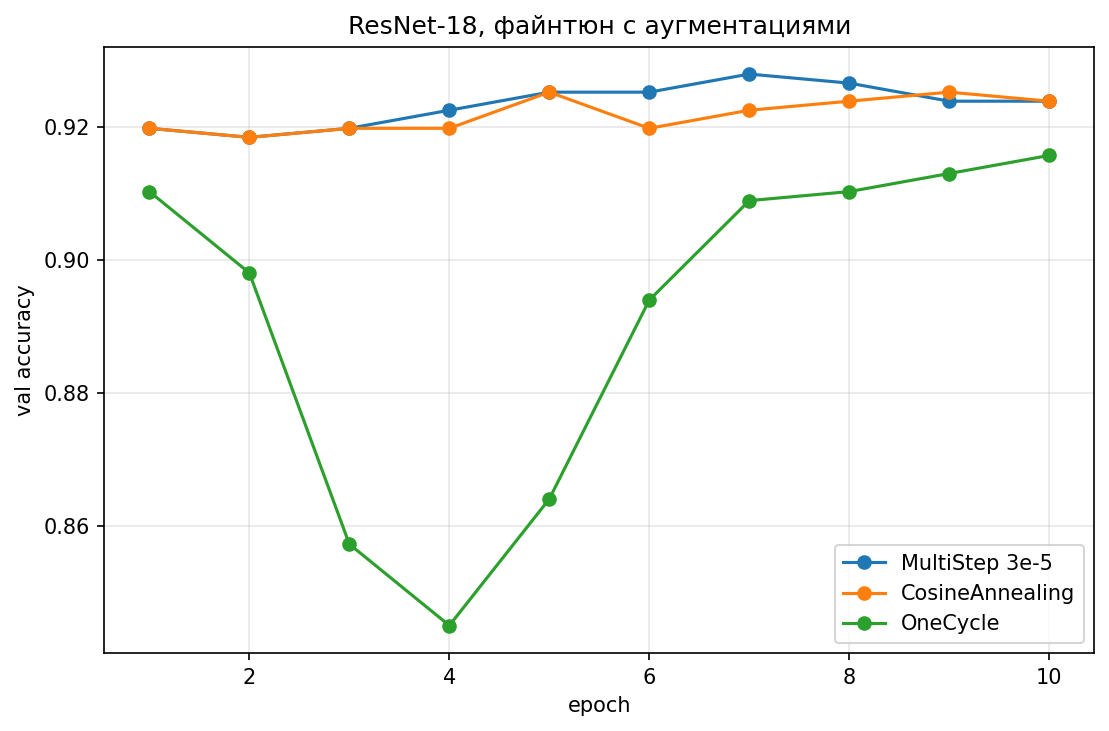

In [1]:
# Самодостаточный прогон. Веса шага 5 жили только в оборванном ядре,
# поэтому голова ResNet-18 обучается здесь, и три планировщика стартуют от её копий.
import copy
import os
import time
import warnings
from pathlib import Path

import torch
import torch.nn as nn
import torchmetrics
from IPython.display import Image, display
from torchvision.models import ResNet18_Weights, resnet18

warnings.filterwarnings("ignore")

if not (Path.cwd() / "utils").exists():
    os.chdir(r"C:\go\Projects\spbu_dl_2026\notebooks")

from utils.common import seed_everything
from utils.data import augmented_transform, make_dataloaders
from utils.plotting import plot_val_histories
from utils.training import train

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_loader, val_loader, _, num_classes, _ = make_dataloaders(batch_size=64)
train_loader_aug, _, _, _, _ = make_dataloaders(batch_size=64, train_transform=augmented_transform)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=num_classes).to(device)

# Планировщик шагает раз за эпоху. Проверяем, что OneCycle на 10 шагов не падает.
_probe = nn.Linear(1, 1)
_opt = torch.optim.AdamW(_probe.parameters(), lr=3e-5)
_sch = torch.optim.lr_scheduler.OneCycleLR(_opt, max_lr=3e-4, total_steps=10)
for _ in range(10):
    _opt.step()
    _sch.step()
del _probe, _opt, _sch


def train_timed(label, model, loader, optimizer, epochs=10, scheduler=None):
    started = time.perf_counter()
    history = train(
        model, loader, val_loader, criterion, accuracy_metric, optimizer, device,
        epochs=epochs, scheduler=scheduler,
    )
    elapsed = time.perf_counter() - started
    best = max(history["val_accuracy"])
    print(f"{label}: {elapsed:.1f} c ({elapsed / epochs:.1f} c/эпоху), лучшая val accuracy {best:.4f}")
    return history


seed_everything(123)
model_head = resnet18(weights=ResNet18_Weights.DEFAULT)
for param in model_head.parameters():
    param.requires_grad = False
model_head.fc = nn.Linear(model_head.fc.in_features, num_classes)
model_head = model_head.to(device)
optimizer = torch.optim.Adam([p for p in model_head.parameters() if p.requires_grad], lr=1e-3)
history_head = train_timed("доп 3: голова -- ResNet-18", model_head, train_loader, optimizer)

scheduler_histories = {}
for schedule_name, make_scheduler in [
    ("MultiStep 3e-5", lambda opt: torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[8], gamma=0.1)),
    ("CosineAnnealing", lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=10)),
    ("OneCycle", lambda opt: torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-4, total_steps=10)),
]:
    model_sch = copy.deepcopy(model_head)
    for param in model_sch.parameters():
        param.requires_grad = True
    seed_everything(123)
    optimizer = torch.optim.AdamW(model_sch.parameters(), lr=3e-5, weight_decay=1e-4)
    history = train_timed(
        f"доп 3: {schedule_name} -- ResNet-18",
        model_sch,
        train_loader_aug,
        optimizer,
        scheduler=make_scheduler(optimizer),
    )
    scheduler_histories[schedule_name] = history["val_accuracy"]
    del model_sch

plot_val_histories(
    scheduler_histories,
    "ResNet-18, файнтюн с аугментациями",
    "../images/schedulers_val_accuracy.png",
)
display(Image(filename="../images/schedulers_val_accuracy.png"))


### Задание 4. Learning rate и узкий MobileNet

Шаг 5 для MobileNetV2 повторяется с lr `3e-4` вместо `3e-5`: та же обученная голова, те же аугментации, AdamW и MultiStepLR. Затем `mobilenet_v2(width_mult=0.5, weights=None)` — готовых весов нет, поэтому это обучение с нуля тем же оптимизатором и тем же lr `3e-4`. Сравниваем число параметров, val accuracy и скорость инференса с обычным MobileNetV2 после файнтюна.

Голова MobileNetV2 обучается в ячейке ниже. Accuracy для lr `3e-5` берётся из уже выполненного шага 5 (лучшая val accuracy 0.9171), без повторного обучения.

**Ответ.** Файнтюн с lr `3e-4` дал лучшую val accuracy 0.923 на 5-й эпохе против 0.917 у шага 5 с lr `3e-5`. Дальше val loss вырос с 0.269 до 0.336. Сеть `width_mult=0.5` без предобучения: 735 077 параметров против 2 271 269, в 3.09 раза меньше, лучшая val accuracy 0.098 за 10 эпох. Инференс val: 4.5 с и 165 картинок/с против 7.6 с и 97 картинок/с у ширины 1.0.


In [2]:
# Самодостаточный прогон. Голова MobileNetV2 обучается здесь.
# lr 3e-5 не переобучаем: лучшая val accuracy шага 5 уже сохранена в выводе той ячейки.
import os
import time
import warnings
from pathlib import Path

import torch
import torch.nn as nn
import torchmetrics
from torchvision.models import MobileNet_V2_Weights, mobilenet_v2

warnings.filterwarnings("ignore")

if not (Path.cwd() / "utils").exists():
    os.chdir(r"C:\go\Projects\spbu_dl_2026\notebooks")

from utils.common import seed_everything
from utils.data import augmented_transform, make_dataloaders
from utils.training import train

# Ячейка шага 5, полный файнтюн MobileNetV2 с аугментациями, AdamW lr 3e-5.
STEP5_MB_BEST_VAL = 0.9171
STEP5_MB_INFER_S = 8.45
STEP5_MB_IPS = 87

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_loader, val_loader, _, num_classes, _ = make_dataloaders(batch_size=64)
train_loader_aug, _, _, _, _ = make_dataloaders(batch_size=64, train_transform=augmented_transform)
criterion = nn.CrossEntropyLoss()
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=num_classes).to(device)


def train_timed(label, model, loader, optimizer, epochs=10, scheduler=None):
    started = time.perf_counter()
    history = train(
        model, loader, val_loader, criterion, accuracy_metric, optimizer, device,
        epochs=epochs, scheduler=scheduler,
    )
    elapsed = time.perf_counter() - started
    best = max(history["val_accuracy"])
    print(f"{label}: {elapsed:.1f} c ({elapsed / epochs:.1f} c/эпоху), лучшая val accuracy {best:.4f}")
    return history


@torch.no_grad()
def measure_inference_time(model, data_loader, device):
    model.eval()
    if device.type == "cuda":
        torch.cuda.synchronize()
    started = time.perf_counter()
    n_images = 0
    for inputs, _ in data_loader:
        model(inputs.to(device, non_blocking=True))
        n_images += inputs.size(0)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - started
    return elapsed, n_images / elapsed


seed_everything(123)
model_mb = mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)
for param in model_mb.parameters():
    param.requires_grad = False
model_mb.classifier[1] = nn.Linear(model_mb.classifier[1].in_features, num_classes)
model_mb = model_mb.to(device)
optimizer = torch.optim.Adam([p for p in model_mb.parameters() if p.requires_grad], lr=1e-3)
history_head = train_timed("доп 4: голова -- MobileNetV2", model_mb, train_loader, optimizer)

for param in model_mb.parameters():
    param.requires_grad = True
seed_everything(123)
optimizer = torch.optim.AdamW(model_mb.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[8], gamma=0.1)
history_mb_lr = train_timed(
    "доп 4: MobileNetV2 lr=3e-4",
    model_mb,
    train_loader_aug,
    optimizer,
    scheduler=scheduler,
)

thin = mobilenet_v2(width_mult=0.5, weights=None)
thin.classifier[1] = nn.Linear(thin.classifier[1].in_features, num_classes)
thin = thin.to(device)
full_ref = mobilenet_v2(weights=None)
full_ref.classifier[1] = nn.Linear(full_ref.classifier[1].in_features, num_classes)
n_full = sum(p.numel() for p in full_ref.parameters())
n_thin = sum(p.numel() for p in thin.parameters())
print(f"параметры: width 1.0 = {n_full:,}, width 0.5 = {n_thin:,}, отношение {n_full / n_thin:.2f}x")

seed_everything(123)
optimizer = torch.optim.AdamW(thin.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[8], gamma=0.1)
history_thin = train_timed(
    "доп 4: MobileNetV2 width 0.5 с нуля",
    thin,
    train_loader_aug,
    optimizer,
    scheduler=scheduler,
)

elapsed_full, ips_full = measure_inference_time(full_ref.to(device), val_loader, device)
elapsed_thin, ips_thin = measure_inference_time(thin, val_loader, device)
print(
    f"val accuracy: lr 3e-5 шаг 5 {STEP5_MB_BEST_VAL:.4f}, "
    f"lr 3e-4 {max(history_mb_lr['val_accuracy']):.4f}, "
    f"width 0.5 с нуля {max(history_thin['val_accuracy']):.4f}"
)
print(
    f"инференс сейчас: width 1.0 {elapsed_full:.1f} c ({ips_full:.0f} картинок/с), "
    f"width 0.5 {elapsed_thin:.1f} c ({ips_thin:.0f} картинок/с)"
)
print(
    f"инференс width 1.0 на шаге 5 был {STEP5_MB_INFER_S:.2f} c ({STEP5_MB_IPS:.0f} картинок/с): "
    "скорость задаёт архитектура"
)


Epoch 1/10


  train loss=2.6577 | val loss=1.7812  | val accuracy=0.7364
Epoch 2/10


  train loss=1.3535 | val loss=1.1127  | val accuracy=0.8125
Epoch 3/10


  train loss=0.8865 | val loss=0.8737  | val accuracy=0.8424
Epoch 4/10


  train loss=0.6662 | val loss=0.7438  | val accuracy=0.8560
Epoch 5/10


...

  train loss=3.3675 | val loss=3.3264  | val accuracy=0.0856
Epoch 8/10


  train loss=3.3148 | val loss=3.2960  | val accuracy=0.0938
Epoch 9/10


  train loss=3.2564 | val loss=3.2416  | val accuracy=0.0978
Epoch 10/10


  train loss=3.2361 | val loss=3.2293  | val accuracy=0.0938
доп 4: MobileNetV2 width 0.5 с нуля: 830.3 c (83.0 c/эпоху), лучшая val accuracy 0.0978


val accuracy: lr 3e-5 шаг 5 0.9171, lr 3e-4 0.9226, width 0.5 с нуля 0.0978
инференс сейчас: width 1.0 7.6 c (97 картинок/с), width 0.5 4.5 c (165 картинок/с)
инференс width 1.0 на шаге 5 был 8.45 c (87 картинок/с): скорость задаёт архитектура
